## TAREA 2 - PROBLEMAS DE CLASIFICACIÓN
#### *Machine Learning*

**Presentado por:**
- Violeta Isabella España Bolaños
- Sebastian Giraldo Acosta
- David Vergara
- Luis Murillo
- Juan David Velasco
---

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, f1_score

SEMILLA = 42
np.random.seed(SEMILLA)

### 0. Selección de Dataset

Para el desarrollo de la Tarea 2 seleccionamos el dataset *"Estimation of Obesity Levels Based on Eating Habits and Physical Condition"*, publicado en el repositorio UCI. Reúne 2.111 registros de personas de Colombia, México y Perú, con 17 variables sobre sus datos físicos, hábitos de alimentación, actividad física y antecedentes familiares. Cada persona está clasificada en uno de siete niveles de peso, desde peso insuficiente hasta obesidad tipo III.

In [21]:
# En Colab/entorno nuevo: !pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# fetch dataset 
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544) 
  
# data (as pandas dataframes) 
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features 
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets

In [22]:
dataset = pd.concat([X, y], axis=1)
print("Dimensiones:", dataset.shape)
dataset.head()

Dimensiones: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [23]:
duplicados = dataset.duplicated().sum()
print("Cantidad de duplicados:", duplicados)

Cantidad de duplicados: 24


In [24]:
dataset = dataset.drop_duplicates()
print("Duplicados restantes:", dataset.duplicated().sum())

Duplicados restantes: 0


#### Codificación de variables categóricas de entrada

In [25]:
data = dataset.copy()

# 1. Codificación de variables binarias
data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})

for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    data[col] = data[col].map({"no": 0, "yes": 1})


# 2. Codificación de variables ordinales
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    data[col] = data[col].round().astype(int)

orden_frecuencia = {
    "no": 0,
    "Sometimes": 1,
    "Frequently": 2,
    "Always": 3
}

data["CAEC"] = data["CAEC"].map(orden_frecuencia)

# Agrupar "Always" con "Frequently" porque solo hay un registro
data["CALC"] = data["CALC"].replace("Always", "Frequently")
data["CALC"] = data["CALC"].map(orden_frecuencia)


# 3. Codificación de variables nominales
data["MTRANS"] = data["MTRANS"].replace({
    "Bike": "Two_Wheels",
    "Motorbike": "Two_Wheels"
})

data = pd.get_dummies(
    data,
    columns=["MTRANS"],
    prefix="MTRANS",
    dtype=int
)


# 4. Codificación de la variable objetivo
niveles = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6
}

data["NObeyesdad"] = data["NObeyesdad"].map(niveles)

nombres_clases = {v: k for k, v in niveles.items()}


# 5. Separación de variables predictoras y objetivo
X = data.drop(columns=["NObeyesdad"])
y = data["NObeyesdad"]


# 6. Selección de variables que requieren escalado
columnas_numericas = [
    "Age", "Height", "Weight",
    "FCVC", "NCP", "CH2O",
    "FAF", "TUE", "CAEC", "CALC"
]


# 7. Configuración del preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        ("escalado", StandardScaler(), columnas_numericas)
    ],
    remainder="passthrough"
)


# 8. Verificación de la transformación
print(f"Dimensiones: {data.shape}")
print(f"Nulos totales: {data.isna().sum().sum()}")
print(f"Columnas no numéricas: {data.select_dtypes(exclude='number').columns.tolist()}")

print("\nValores únicos por columna (excepto continuas):")

for col in data.columns.drop(["Age", "Height", "Weight"]):
    print(f"  {col:32s} {sorted(data[col].unique().tolist())}")

data.head()

Dimensiones: (2087, 20)
Nulos totales: 0
Columnas no numéricas: []

Valores únicos por columna (excepto continuas):
  Gender                           [0, 1]
  family_history_with_overweight   [0, 1]
  FAVC                             [0, 1]
  FCVC                             [1, 2, 3]
  NCP                              [1, 2, 3, 4]
  CAEC                             [0, 1, 2, 3]
  SMOKE                            [0, 1]
  CH2O                             [1, 2, 3]
  SCC                              [0, 1]
  FAF                              [0, 1, 2, 3]
  TUE                              [0, 1, 2]
  CALC                             [0, 1, 2]
  NObeyesdad                       [0, 1, 2, 3, 4, 5, 6]
  MTRANS_Automobile                [0, 1]
  MTRANS_Public_Transportation     [0, 1]
  MTRANS_Two_Wheels                [0, 1]
  MTRANS_Walking                   [0, 1]


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,NObeyesdad,MTRANS_Automobile,MTRANS_Public_Transportation,MTRANS_Two_Wheels,MTRANS_Walking
0,0,21.0,1.62,64.0,1,0,2,3,1,0,2,0,0,1,0,1,0,1,0,0
1,0,21.0,1.52,56.0,1,0,3,3,1,1,3,1,3,0,1,1,0,1,0,0
2,1,23.0,1.80,77.0,1,0,2,3,1,0,2,0,2,1,2,1,0,1,0,0
3,1,27.0,1.80,87.0,0,0,3,3,1,0,2,0,2,0,2,2,0,0,0,1
4,1,22.0,1.78,89.8,0,0,2,1,1,0,2,0,0,0,1,3,0,1,0,0


#### División del Dataset

In [26]:
# Separar características y variable objetivo
X = data.drop(columns=["NObeyesdad"])
y = data["NObeyesdad"]

# 70% entrenamiento y 30% restante
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEMILLA, stratify=y)

# 20% validación y 10% prueba
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=1/3, random_state=SEMILLA, stratify=y_temp)

### 1. Regularización L1 y L2 en tareas de clasificación (Punto 1.a)

La regularización es una técnica para controlar la complejidad de un modelo y reducir el sobreajuste (*overfitting*): evita que el modelo aprenda los detalles de los datos de entrenamiento a costa de generalizar peor. Para ello se agrega a la función de pérdida un término de penalización que castiga los pesos grandes.

#### 1.1. Cómo funciona

Sea $\mathcal{J}(\mathbf{w}, b)$ la entropía cruzada promedio (punto 1.b). El modelo regularizado minimiza:
$$\mathcal{J}_{reg}(\mathbf{w}, b) = \mathcal{J}(\mathbf{w}, b) + \lambda \, R(\mathbf{w})$$

donde $\lambda \ge 0$ controla la intensidad de la penalización y $R$ depende del tipo de regularización. El intercepto $b$ **no se penaliza**.

| | Penalización $R(\mathbf{w})$ | Aporte al gradiente | Efecto |
|---|---|---|---|
| **L1 (Lasso)** | $\lVert\mathbf{w}\rVert_1 = \sum_j \lvert w_j \rvert$ | $\lambda \cdot \text{signo}(w_j)$ | Empuja cada peso hacia 0 con fuerza **constante**, sin importar su tamaño, por lo que muchos pesos llegan a ser **exactamente 0**. Selecciona variables automáticamente (modelo disperso). |
| **L2 (Ridge)** | $\tfrac{1}{2}\lVert\mathbf{w}\rVert_2^2 = \tfrac{1}{2}\sum_j w_j^2$ | $\lambda \, w_j$ | Empuja cada peso con fuerza **proporcional** a su tamaño: los encoge de forma suave, pero casi nunca los lleva exactamente a 0. Conserva todas las variables. |
| **Elastic-Net** | $\rho\lVert\mathbf{w}\rVert_1 + \tfrac{1-\rho}{2}\lVert\mathbf{w}\rVert_2^2$ | combinación de ambos | Mezcla las dos ($\rho$ = `l1_ratio`). |

La L1 no es derivable en $w_j = 0$ (se usa un subgradiente), y justamente ese "pico" en el origen es lo que permite que los pesos se queden en cero.

#### 1.2. Cómo se implementa en sklearn

`LogisticRegression` no recibe $\lambda$ sino `C`, el **inverso** de la intensidad de regularización. Internamente minimiza
$$C \sum_{i=1}^{m} \text{pérdida}_i \; + \; R(\mathbf{w}) \qquad \Longleftrightarrow \qquad \mathcal{J}(\mathbf{w}, b) + \frac{1}{C\,m}\,R(\mathbf{w}), \qquad \text{es decir,} \quad \lambda = \frac{1}{C\,m}$$

Por eso **`C` pequeño = regularización fuerte** y `C` grande = regularización débil (con $C \to \infty$ se recupera el modelo sin regularizar). En el punto 1.b se verifica numéricamente esta equivalencia $\lambda = 1/(C\,m)$.

| Parámetro | Qué controla |
|---|---|
| `penalty` | `'l1'`, `'l2'` (por defecto), `'elasticnet'` o `None` |
| `C` | Inverso de la intensidad de regularización (`1.0` por defecto) |
| `l1_ratio` | Peso de L1 en Elastic-Net ($\rho$) |
| `solver` | Algoritmo de optimización; limita qué penalizaciones se pueden usar |

| Solver | Penalizaciones admitidas |
|---|---|
| `lbfgs`, `newton-cg`, `newton-cholesky`, `sag` | L2 o sin regularización |
| `saga` | L1, L2, Elastic-Net o sin regularización |
| `liblinear` | L1 o L2 (solo One-vs-Rest, no admite `penalty=None`) |

Por eso **L1 se entrena con `saga`**, el único solver que admite L1 con la formulación multinomial.

> **Nota sobre la API.** Desde la versión 1.8 de sklearn el parámetro `penalty` está deprecado en favor de `l1_ratio` y `C` (`penalty='l2'` equivale a `l1_ratio=0`, `'l1'` a `l1_ratio=1`, `'elasticnet'` a `0 < l1_ratio < 1` y `None` a `C=np.inf`). Este notebook conserva `penalty` porque sigue funcionando y es la forma usada en clase; los `FutureWarning` resultantes se silencian en la celda de configuración.

#### 1.3. Importancia del escalado

La penalización depende de la magnitud de los pesos, y esta depende de la escala de cada variable. Por eso las variables se estandarizan (`StandardScaler`) **dentro del `Pipeline`**: así el escalado se ajusta solo con cada partición de entrenamiento durante la validación cruzada y no se filtra información.

#### 1.4. Diseño del experimento

- Se evalúan 8 valores de `C` entre $10^{-3}$ y $10^{4}$ con validación cruzada estratificada de 5 particiones y la métrica **F1 macro** (promedia las 7 clases por igual).
- **L1** con `solver='saga'` y **L2** con `solver='newton-cholesky'`. Como la pérdida es convexa, para L2 cualquier solver llega al mismo óptimo (se verifica en el punto 1.d), así que la diferencia de solver no sesga la comparación.
- Se agrega como referencia el modelo **sin regularización** (`penalty=None`).
- La comparación final se hace sobre el conjunto de validación, que no se usó para elegir `C`.

In [ ]:
import os
import warnings

# Silencia los avisos de deprecación del parámetro `penalty` (sklearn >= 1.8).
# La variable de entorno también alcanza a los procesos paralelos de GridSearchCV (n_jobs=-1).
os.environ["PYTHONWARNINGS"] = (
    "ignore:'penalty' was deprecated:FutureWarning,"
    "ignore:Inconsistent values:UserWarning"
)
warnings.filterwarnings("ignore", message=".*penalty.*", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*Inconsistent values.*", category=UserWarning)

# Configuración de hiperparámetros
# Valores de C que se evaluarán (8 valores, de regularización muy fuerte a muy débil)
# C pequeño = regularización más fuerte
# C grande = regularización más débil
parametros = {
    "clasificador__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]
}

# Validación cruzada estratificada de 5 particiones
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA
)

In [ ]:
modelo_L1 = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(
        penalty="l1",       # L1: favorece que algunos coeficientes sean exactamente cero
        solver="saga",      # Solver compatible con regularización L1 y clasificación multiclase
        max_iter=5000,      # Mayor número de iteraciones para favorecer la convergencia
        random_state=SEMILLA
    ))
])

busqueda_L1 = GridSearchCV(
    estimator=modelo_L1,
    param_grid=parametros,
    scoring="f1_macro",    # Evalúa el rendimiento promedio de las siete clases
    cv=cv,
    n_jobs=-1,
    refit=True
)

busqueda_L1.fit(X_train, y_train);

In [ ]:
modelo_L2 = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(
        penalty="l2",       # L2: reduce la magnitud de los coeficientes
        solver="newton-cholesky",      # Problema convexo: llega al mismo óptimo que cualquier otro solver L2
        max_iter=5000,      # Mayor número de iteraciones para favorecer la convergencia
        random_state=SEMILLA
    ))
])

busqueda_L2 = GridSearchCV(
    estimator=modelo_L2,
    param_grid=parametros,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

busqueda_L2.fit(X_train, y_train);

#### Comparación F1 - Regularización L1 y L2

In [11]:
print("RESULTADOS DE LA BÚSQUEDA DE HIPERPARÁMETROS")

print("\nRegularización L1")
print("Mejor C:", busqueda_L1.best_params_["clasificador__C"])
print("Mejor F1-score macro:", busqueda_L1.best_score_)

print("\nRegularización L2")
print("Mejor C:", busqueda_L2.best_params_["clasificador__C"])
print("Mejor F1-score macro:", busqueda_L2.best_score_)

RESULTADOS DE LA BÚSQUEDA DE HIPERPARÁMETROS

Regularización L1
Mejor C: 10
Mejor F1-score macro: 0.9563334596540356

Regularización L2
Mejor C: 10000
Mejor F1-score macro: 0.9603697185489729


,C,L1 (media),L1 (desv.),L2 (media),L2 (desv.)
0,0.001,0.0399,0.0014,0.4106,0.0174
1,0.010,0.3929,0.0090,0.5663,0.0174
2,0.100,0.8155,0.0174,0.7344,0.0184
3,1.000,0.9476,0.0140,0.8559,0.0195
4,10.000,0.9563,0.0083,0.9268,0.0110
5,100.000,0.9531,0.0078,0.9452,0.0107
6,1000.000,0.9524,0.0076,0.9553,0.0078
7,10000.000,0.9524,0.0076,0.9604,0.0077


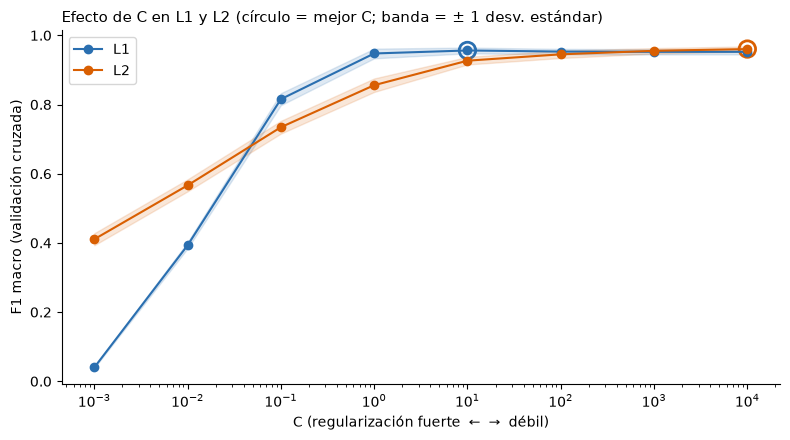

In [12]:
from IPython.display import display

# F1 macro (validación cruzada) para cada valor de C
Cs = parametros["clasificador__C"]
tabla_cv = pd.DataFrame({
    "C": Cs,
    "L1 (media)": busqueda_L1.cv_results_["mean_test_score"],
    "L1 (desv.)": busqueda_L1.cv_results_["std_test_score"],
    "L2 (media)": busqueda_L2.cv_results_["mean_test_score"],
    "L2 (desv.)": busqueda_L2.cv_results_["std_test_score"],
})
display(tabla_cv.round(4))

fig, eje = plt.subplots(figsize=(8, 4.5))
for etiqueta, busqueda, color in [("L1", busqueda_L1, "#2a6fb0"), ("L2", busqueda_L2, "#d95f02")]:
    media = busqueda.cv_results_["mean_test_score"]
    desv = busqueda.cv_results_["std_test_score"]
    eje.plot(Cs, media, marker="o", color=color, label=etiqueta)
    eje.fill_between(Cs, media - desv, media + desv, color=color, alpha=0.15)
    eje.scatter([busqueda.best_params_["clasificador__C"]], [busqueda.best_score_],
                s=140, facecolors="none", edgecolors=color, linewidths=2)
eje.set_xscale("log")
eje.set_xlabel("C (regularización fuerte  ←  →  débil)")
eje.set_ylabel("F1 macro (validación cruzada)")
eje.set_title("Efecto de C en L1 y L2 (círculo = mejor C; banda = ± 1 desv. estándar)", loc="left", fontsize=11)
eje.legend()
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

Total de coeficientes del modelo: 133 (7 clases x 19 variables)


,C,L1: coeficientes en 0,L2: coeficientes en 0
0,0.001,133,0
1,0.010,126,0
2,0.100,85,0
3,1.000,56,0
4,10.000,35,0
5,100.000,9,0
6,1000.000,1,0
7,10000.000,0,0


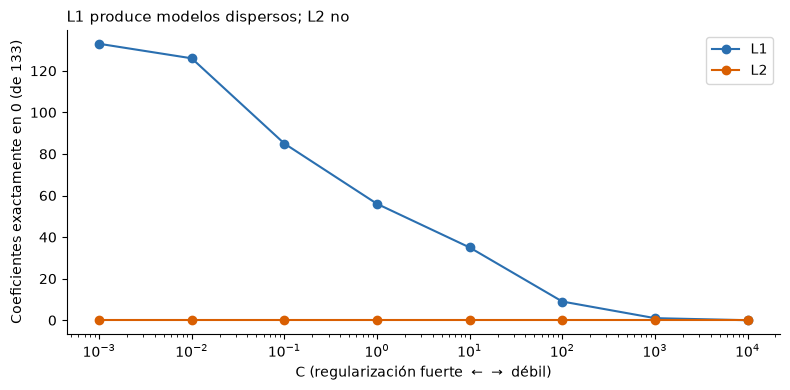

In [13]:
from joblib import Parallel, delayed
from sklearn.base import clone

def coeficientes_en_cero(penalizacion, solver, C):
    # Entrena con un C dado y cuenta cuántos coeficientes quedaron exactamente en 0
    modelo = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", LogisticRegression(penalty=penalizacion, solver=solver, C=C,
                                            max_iter=5000, random_state=SEMILLA))
    ])
    modelo.fit(X_train, y_train)
    return int((modelo.named_steps["clasificador"].coef_ == 0).sum())

ceros_L1 = Parallel(n_jobs=-1)(delayed(coeficientes_en_cero)("l1", "saga", C) for C in Cs)
ceros_L2 = Parallel(n_jobs=-1)(delayed(coeficientes_en_cero)("l2", "newton-cholesky", C) for C in Cs)
total_coef = busqueda_L1.best_estimator_.named_steps["clasificador"].coef_.size   # 7 clases x 19 variables

tabla_ceros = pd.DataFrame({"C": Cs, "L1: coeficientes en 0": ceros_L1, "L2: coeficientes en 0": ceros_L2})
print(f"Total de coeficientes del modelo: {total_coef} (7 clases x 19 variables)")
display(tabla_ceros)

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(Cs, ceros_L1, marker="o", color="#2a6fb0", label="L1")
eje.plot(Cs, ceros_L2, marker="o", color="#d95f02", label="L2")
eje.set_xscale("log")
eje.set_xlabel("C (regularización fuerte  ←  →  débil)")
eje.set_ylabel(f"Coeficientes exactamente en 0 (de {total_coef})")
eje.set_title("L1 produce modelos dispersos; L2 no", loc="left", fontsize=11)
eje.legend()
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [72]:
mejor_L1 = busqueda_L1.best_estimator_
mejor_L2 = busqueda_L2.best_estimator_

#### Comparación métricas con Regularización y sin Regularización

In [ ]:
modelo_sin_regularizacion = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(
        penalty=None,             # Sin regularización
        solver="saga", # Mismo optimizador utilizado en L1
        max_iter=5000
    ))
])

modelo_sin_regularizacion.fit(X_train, y_train);

In [16]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# Predicciones
pred_sin_reg = modelo_sin_regularizacion.predict(X_val)
pred_L1 = mejor_L1.predict(X_val)
pred_L2 = mejor_L2.predict(X_val)

# Comparación de métricas
resultados = pd.DataFrame({
    "Modelo": ["Sin regularización", "L1", "L2"],
    "Accuracy": [
        accuracy_score(y_val, pred_sin_reg),
        accuracy_score(y_val, pred_L1),
        accuracy_score(y_val, pred_L2)
    ],
    "Precision macro": [
        precision_score(y_val, pred_sin_reg, average="macro"),
        precision_score(y_val, pred_L1, average="macro"),
        precision_score(y_val, pred_L2, average="macro")
    ],
    "Recall macro": [
        recall_score(y_val, pred_sin_reg, average="macro"),
        recall_score(y_val, pred_L1, average="macro"),
        recall_score(y_val, pred_L2, average="macro")
    ],
    "F1-score macro": [
        f1_score(y_val, pred_sin_reg, average="macro"),
        f1_score(y_val, pred_L1, average="macro"),
        f1_score(y_val, pred_L2, average="macro")
    ]
})

resultados

,Modelo,Accuracy,Precision macro,Recall macro,F1-score macro
0,Sin regularización,0.949761,0.947942,0.948582,0.948130
1,L1,0.954545,0.953109,0.953243,0.953110
2,L2,0.947368,0.945962,0.945353,0.945431


In [17]:
from sklearn.model_selection import cross_val_score

def resumen_modelo(nombre, modelo, f1_cv_media, f1_cv_desv):
    coef = modelo.named_steps["clasificador"].coef_
    return {
        "Modelo": nombre,
        "F1 macro CV (media ± desv.)": f"{f1_cv_media:.4f} ± {f1_cv_desv:.4f}",
        "F1 macro validación": round(f1_score(y_val, modelo.predict(X_val), average="macro"), 4),
        "Coeficientes en 0": f"{int((coef == 0).sum())} de {coef.size}",
        "Máx. |peso|": round(float(np.abs(coef).max()), 1),
    }

filas = []
for nombre, busqueda in [("L1 (mejor C)", busqueda_L1), ("L2 (mejor C)", busqueda_L2)]:
    i = busqueda.best_index_
    filas.append(resumen_modelo(nombre, busqueda.best_estimator_,
                                busqueda.cv_results_["mean_test_score"][i],
                                busqueda.cv_results_["std_test_score"][i]))

# Sin regularización: el resultado depende del solver (ver observaciones)
for solver in ["saga", "newton-cholesky"]:
    modelo = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", LogisticRegression(penalty=None, solver=solver, max_iter=5000))
    ])
    # Sin penalización, newton-cholesky avisa que el Hessiano es singular o mal condicionado (datos casi separables)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        puntajes = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="f1_macro")
        modelo.fit(X_train, y_train)
    filas.append(resumen_modelo(f"Sin regularización ({solver})", modelo, puntajes.mean(), puntajes.std()))

pd.DataFrame(filas)

,Modelo,F1 macro CV (media ± desv.),F1 macro validación,Coeficientes en 0,Máx. |peso|
0,L1 (mejor C),0.9563 ± 0.0083,0.9531,35 de 133,81.3
1,L2 (mejor C),0.9604 ± 0.0077,0.9454,0 de 133,273.5
2,Sin regularización (saga),0.9524 ± 0.0076,0.9481,0 de 133,93.0
3,Sin regularización (newton-cholesky),0.9494 ± 0.0110,0.9286,0 de 133,377.3


**Observaciones (Punto 1.a)**

1. **Demasiada regularización perjudica a ambos modelos.** Con `C` muy pequeño el F1 macro se desploma (L1: 0,04 con `C` = 0,001 y 0,82 con `C` = 0,1; L2: 0,41 y 0,73). En L1 con `C` = 0,001 los 133 coeficientes quedan en 0 y el modelo predice una sola clase. Con `C` = 1 ya se recupera (0,95 en L1 y 0,86 en L2). L2 necesita un `C` mayor porque encoge los pesos sin anularlos.
2. **L1 y L2 rinden prácticamente igual.** El mejor L1 (`C` = 10) obtiene un F1 macro en validación cruzada de 0,9563 ± 0,0083 y el mejor L2 (`C` = 10000) 0,9604 ± 0,0077. La diferencia (0,004) es menor que la desviación estándar entre particiones, así que no es significativa. En validación (418 registros) L1 obtiene 0,9531 de F1 y L2 0,9454; en accuracy la diferencia son 3 registros (0,9545 vs. 0,9474). No se puede afirmar que uno sea mejor que el otro.
3. **La diferencia real está en la dispersión.** L1 deja en 0 el 26 % de los coeficientes (35 de 133) con su mejor `C`, sin perder desempeño, y con `C` = 1 llega al 42 % (56 de 133) con un F1 macro CV de 0,9476, cercano a su máximo. L2 no deja ningún coeficiente en 0 con ningún valor de `C`. Por eso L1 entrega un modelo más simple, útil para seleccionar variables.
4. **L2 prefiere una regularización casi nula en estos datos.** Su mejor `C` está en el borde de la rejilla ampliada (10000) y la curva sigue subiendo despacio (0,927, 0,945, 0,955 y 0,960 con `C` = 10, 100, 1000 y 10000). Con todas las variables, incluidas `Weight` y `Height`, las clases son casi separables (en el punto 1.b la pérdida de sklearn sin regularizar llega a 0,0001), y en ese caso penalizar poco permite pesos grandes que separan mejor.
5. **«Sin regularización» no es una referencia única.** Con datos casi separables el óptimo sin penalización no existe (los pesos crecen sin límite), así que el resultado depende de cuándo se detiene el solver: `saga` (máx. |peso| = 93) obtiene 0,9481 de F1 en validación y `newton-cholesky` (máx. |peso| = 377) obtiene 0,9286; este último incluso avisa que el Hessiano es singular o mal condicionado. Esa diferencia de 0,02 se debe solo al solver. La regularización sí acota los pesos: L1 con su mejor `C` llega a un máx. |peso| de 81, mientras que L2 con `C` = 10000 (penalización casi nula) llega a 273.
6. **Conclusión.** En este dataset la regularización no mejora de forma apreciable el F1 macro (todos los modelos están entre 0,95 y 0,96, dentro del ruido de la validación). Su aporte es otro: L1 produce un modelo más simple con el mismo desempeño y acota los pesos, y la regularización fuerte (`C` ≤ 0,1) reduce el desempeño. Esto corrige la lectura preliminar de que L2 empeoraba por regularizar demasiado: con la rejilla original (`C` ≤ 100) L2 parecía peor solo porque su mejor valor quedaba fuera de la rejilla.

#### Nota sobre las variables utilizadas (`Weight` y `Height`)

En esta tarea los modelos usan **todas** las variables, incluidas `Weight` y `Height`. Como la clase se define a partir del IMC (`Weight / Height²`), esas dos variables concentran casi toda la información: el modelo puede recalcular el IMC en lugar de aprender de los hábitos. La celda siguiente mide cuánto cambia el F1 macro en validación si se las quita.

In [18]:
sin_peso_altura = [c for c in columnas_numericas if c not in ("Weight", "Height")]
preprocesador_sin = ColumnTransformer(
    transformers=[("escalado", StandardScaler(), sin_peso_altura)],
    remainder="passthrough"
)

X_train_sin = X_train.drop(columns=["Weight", "Height"])
X_val_sin = X_val.drop(columns=["Weight", "Height"])

filas = []
for nombre, mejor in [("L1", mejor_L1), ("L2", mejor_L2)]:
    con_variables = f1_score(y_val, mejor.predict(X_val), average="macro")
    modelo_sin = clone(mejor).set_params(preprocesamiento=preprocesador_sin).fit(X_train_sin, y_train)
    sin_variables = f1_score(y_val, modelo_sin.predict(X_val_sin), average="macro")
    filas.append({"Modelo": nombre,
                  "F1 macro con Weight y Height": round(con_variables, 4),
                  "F1 macro sin Weight ni Height": round(sin_variables, 4)})
pd.DataFrame(filas)

,Modelo,F1 macro con Weight y Height,F1 macro sin Weight ni Height
0,L1,0.9531,0.5748
1,L2,0.9454,0.5776


Al quitar `Weight` y `Height`, el F1 macro en validación cae de 0,953 a 0,575 en L1 y de 0,945 a 0,578 en L2. Es decir, los resultados altos de esta tarea (alrededor de 0,95) provienen casi por completo de esas dos variables, algo esperable porque la clase se define con el IMC. Se mantienen en este notebook porque el enunciado no exige excluirlas, pero conviene tenerlo presente al interpretar los resultados, y es una decisión que el equipo debe definir, pues en el proyecto final se excluyen del modelo preventivo. Repetir el análisis de regularización sin `Weight` ni `Height` (donde L1 seleccionaría entre hábitos) queda como una posible extensión.

### 2. Pérdida de entropía cruzada (Punto 1.b)

La **Entropía Cruzada (*Cross-Entropy Loss*)**, también denominada *Log-Loss* o pérdida de log-verosimilitud negativa, es la función de coste estándar y probabilísticamente óptima para el entrenamiento de modelos de clasificación supervisada como la regresión logística.

---

#### 2.1. Marco Teórico y Justificación Probabilística
Sea un problema de clasificación binaria donde la etiqueta objetivo real $y \in \{0, 1\}$ sigue una distribución de Bernoulli con probabilidad condicional $p = P(y = 1 \mid \mathbf{x})$.  
El modelo de Regresión Logística estima esta probabilidad mediante la transformación sigmoide del predictor lineal $z$:
$$z = \mathbf{w}^T \mathbf{x} + b = \sum_{j=1}^p w_j x_j + b$$
$$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

La probabilidad de observar una etiqueta $y$ dada la predicción $\hat{y}$ se modela como:
$$P(y \mid \mathbf{x}) = \hat{y}^y (1 - \hat{y})^{1 - y}$$

Asumiendo que las $m$ muestras del conjunto de entrenamiento son independientes e idénticamente distribuidas (i.i.d.), la **Función de Verosimilitud (*Likelihood*)** conjunta es:
$$L(\mathbf{w}, b) = \prod_{i=1}^m P(y^{(i)} \mid \mathbf{x}^{(i)}) = \prod_{i=1}^m (\hat{y}^{(i)})^{y^{(i)}} (1 - \hat{y}^{(i)})^{1 - y^{(i)}}$$

Aplicando el logaritmo natural ($\ln$) para convertir el producto en una sumatoria y multiplicando por $-\frac{1}{m}$ para transformar el problema de maximización en uno de minimización, se obtiene la **Función de Pérdida de Entropía Cruzada Binaria**:
$$\mathcal{J}(\mathbf{w}, b) = -\frac{1}{m} \ln L(\mathbf{w}, b) = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)} \ln(\hat{y}^{(i)}) + (1 - y^{(i)}) \ln(1 - \hat{y}^{(i)}) \right]$$

Para una muestra individual $i$, la pérdida puntual es:
$$\mathcal{L}^{(i)} = - \left[ y^{(i)} \ln(\hat{y}^{(i)}) + (1 - y^{(i)}) \ln(1 - \hat{y}^{(i)}) \right]$$

---

#### 2.2. ¿Por qué se utiliza Entropía Cruzada en lugar del Error Cuadrático Medio (MSE)?
1. **Convexidad:** Al combinar la función sigmoide con el Error Cuadrático Medio ($MSE = \frac{1}{m}\sum(\hat{y}-y)^2$), la función de pérdida resultante es **no convexa**, con mesetas y mínimos locales donde los algoritmos de optimización se estancan. En contraste, la entropía cruzada con sigmoide es **convexa**: su matriz Hessiana es $\mathbf{H} = \frac{1}{m}\mathbf{X}^T \mathbf{S} \mathbf{X}$ con $\mathbf{S} = \text{diag}\big(\hat{y}^{(i)}(1-\hat{y}^{(i)})\big)$, que es semidefinida positiva. Por eso **todo mínimo local es global** y el gradiente descendente no queda atrapado en mínimos locales. El mínimo es además único (estricta convexidad) cuando $\mathbf{X}$ tiene rango completo por columnas y las clases **no** son perfectamente separables; si lo son, la pérdida puede acercarse a 0 haciendo crecer los pesos sin límite y no existe un mínimo finito. La regularización L2 (punto 1.a) elimina este problema porque vuelve la pérdida estrictamente convexa.
2. **Eliminación de la Saturación de Gradientes:** En MSE, cuando el modelo está severamente equivocado (por ejemplo, predice $\hat{y} \approx 0$ cuando la etiqueta real es $y=1$), la derivada de la sigmoide $\sigma'(z) \to 0$, haciendo que el gradiente sea casi nulo y el modelo apenas aprenda (*saturación*). Con Entropía Cruzada, el gradiente es directamente proporcional al error residual $(\hat{y} - y)$, permitiendo que el modelo aprenda con máxima velocidad cuando comete errores grandes.

---

#### 2.3. Desarrollo Matemático Formal del Gradiente Descendente por Regla de la Cadena

Deseamos calcular la derivada parcial de la función de coste $\mathcal{J}$ respecto a cada peso $w_j$ ($j = 1, \dots, p$) y respecto al intercepto o sesgo $b$.  
Aplicamos la **regla de la cadena** descomponiendo la función en tres factores diferenciales:
$$\frac{\partial \mathcal{L}^{(i)}}{\partial w_j} = \frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} \cdot \frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} \cdot \frac{\partial z^{(i)}}{\partial w_j}$$

---

##### **Factor 1: Derivada de la pérdida respecto a la probabilidad predicha $\hat{y}^{(i)}$**
$$\frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} = \frac{\partial}{\partial \hat{y}^{(i)}} \left( - y^{(i)} \ln(\hat{y}^{(i)}) - (1 - y^{(i)}) \ln(1 - \hat{y}^{(i)}) \right)$$
$$\frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} = - \frac{y^{(i)}}{\hat{y}^{(i)}} - (1 - y^{(i)}) \cdot \left( \frac{-1}{1 - \hat{y}^{(i)}} \right) = - \frac{y^{(i)}}{\hat{y}^{(i)}} + \frac{1 - y^{(i)}}{1 - \hat{y}^{(i)}}$$

Agrupando bajo un común denominador:
$$\frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} = \frac{-y^{(i)}(1 - \hat{y}^{(i)}) + (1 - y^{(i)})\hat{y}^{(i)}}{\hat{y}^{(i)}(1 - \hat{y}^{(i)})} = \frac{-y^{(i)} + y^{(i)}\hat{y}^{(i)} + \hat{y}^{(i)} - y^{(i)}\hat{y}^{(i)}}{\hat{y}^{(i)}(1 - \hat{y}^{(i)})}$$
$$\mathbf{\frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} = \frac{\hat{y}^{(i)} - y^{(i)}}{\hat{y}^{(i)}(1 - \hat{y}^{(i)})}}$$

---

##### **Factor 2: Derivada de la función sigmoide $\hat{y}^{(i)}$ respecto al combinador lineal $z^{(i)}$**
Sabiendo que $\hat{y}^{(i)} = \sigma(z^{(i)}) = (1 + e^{-z^{(i)}})^{-1}$:
$$\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} = \frac{d}{dz^{(i)}}(1 + e^{-z^{(i)}})^{-1} = -(1 + e^{-z^{(i)}})^{-2} \cdot (-e^{-z^{(i)}}) = \frac{e^{-z^{(i)}}}{(1 + e^{-z^{(i)}})^2}$$
Descomponiendo algebraicamente:
$$\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} = \left( \frac{1}{1 + e^{-z^{(i)}}} \right) \cdot \left( \frac{e^{-z^{(i)}}}{1 + e^{-z^{(i)}}} \right)$$
Dado que $\frac{e^{-z}}{1 + e^{-z}} = \frac{1 + e^{-z} - 1}{1 + e^{-z}} = 1 - \frac{1}{1 + e^{-z}} = 1 - \sigma(z)$:
$$\mathbf{\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} = \hat{y}^{(i)}(1 - \hat{y}^{(i)})}$$

---

##### **Factor 3: Derivada del combinador lineal $z^{(i)}$ respecto al peso $w_j$ y respecto al sesgo $b$**
Dado que $z^{(i)} = \sum_{k=1}^p w_k x_k^{(i)} + b$:
$$\mathbf{\frac{\partial z^{(i)}}{\partial w_j} = x_j^{(i)}}, \qquad \mathbf{\frac{\partial z^{(i)}}{\partial b} = 1}$$

---

##### **Factor 4: Sustitución, cancelación algebraica y gradiente total**
Sustituyendo los tres factores en la regla de la cadena:
$$\frac{\partial \mathcal{L}^{(i)}}{\partial w_j} = \left[ \frac{\hat{y}^{(i)} - y^{(i)}}{\hat{y}^{(i)}(1 - \hat{y}^{(i)})} \right] \cdot \left[ \hat{y}^{(i)}(1 - \hat{y}^{(i)}) \right] \cdot x_j^{(i)}$$

Observe que el denominador $\hat{y}^{(i)}(1 - \hat{y}^{(i)})$ **se cancela exactamente** con la derivada de la función sigmoide:
$$\mathbf{\frac{\partial \mathcal{L}^{(i)}}{\partial w_j} = (\hat{y}^{(i)} - y^{(i)}) x_j^{(i)}}$$

Promediando sobre las $m$ muestras de entrenamiento:
$$\mathbf{\frac{\partial \mathcal{J}(\mathbf{w}, b)}{\partial w_j} = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)}) x_j^{(i)}}$$
$$\mathbf{\frac{\partial \mathcal{J}(\mathbf{w}, b)}{\partial b} = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})}$$

En notación matricial compacta:
$$\mathbf{\nabla_{\mathbf{w}} \mathcal{J}(\mathbf{w}) = \frac{1}{m} \mathbf{X}^T (\hat{\mathbf{y}} - \mathbf{y})}$$

---

#### 2.4. Regla de Actualización del Gradiente Descendente
Con una tasa de aprendizaje (*learning rate*) $\alpha > 0$, la regla de actualización para cada iteración o época $t$ es:
$$\mathbf{w}^{(t+1)} := \mathbf{w}^{(t)} - \alpha \nabla_{\mathbf{w}} \mathcal{J}(\mathbf{w}^{(t)}) = \mathbf{w}^{(t)} - \frac{\alpha}{m} \mathbf{X}^T (\hat{\mathbf{y}} - \mathbf{y})$$
$$b^{(t+1)} := b^{(t)} - \frac{\alpha}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})$$

---

#### 2.5. Generalización al Caso Multiclase: Softmax y Entropía Cruzada Categórica
En problemas multiclase con $K$ categorías ($K=7$ en nuestro dataset de obesidad), la probabilidad de pertenencia a la clase $k$ se generaliza mediante la función **Softmax**:
$$\hat{y}_k = P(y = k \mid \mathbf{x}) = \frac{e^{\mathbf{w}_k^T \mathbf{x} + b_k}}{\sum_{j=1}^K e^{\mathbf{w}_j^T \mathbf{x} + b_j}}$$

Optimizando la función de pérdida de **Entropía Cruzada Categórica**:
$$\mathcal{J}(\mathbf{W}) = - \frac{1}{m} \sum_{i=1}^m \sum_{k=1}^K y_k^{(i)} \ln(\hat{y}_k^{(i)})$$

donde $y_k^{(i)} = 1$ si la observación pertenece a la clase $k$ y $0$ en otro caso. Al derivar analíticamente respecto a los parámetros de cada clase $\mathbf{w}_k$, el gradiente conserva la misma elegante estructura lineal:
$$\mathbf{\nabla_{\mathbf{w}_k} \mathcal{J}(\mathbf{W}) = \frac{1}{m} \mathbf{X}^T (\hat{\mathbf{y}}_k - \mathbf{y}_k)}$$

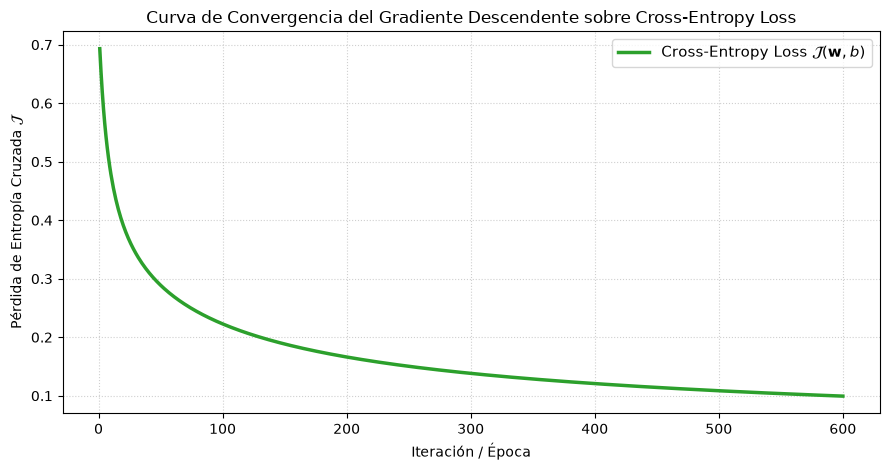

Pérdida inicial (Época 1):   0.6931
Pérdida final tras 600 épocas: 0.0994
Reducción total de pérdida:  0.5938
Accuracy alcanzado en validación: 0.9952 (99.52%)


In [19]:
# ==============================================================================
# IMPLEMENTACIÓN DEL GRADIENTE DESCENDENTE DESDE CERO SOBRE CROSS-ENTROPY LOSS
# Demostración del desarrollo analítico formal realizado en el Punto 1.b
# ==============================================================================

class RegresionLogisticaGDBinaria:
    """
    Clasificador de Regresión Logística entrenado mediante Descenso de Gradiente
    utilizando la función de costo de Entropía Cruzada Binaria derivada analíticamente.
    """
    def __init__(self, learning_rate=0.2, max_iter=600):
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.w = None
        self.b = None
        self.historial_perdida = []
        
    def _sigmoide(self, z):
        # Clip para estabilidad numérica y evitar overflow en exp(-z)
        z = np.clip(z, -250, 250)
        return 1.0 / (1.0 + np.exp(-z))
        
    def fit(self, X, y):
        m, p = X.shape
        self.w = np.zeros(p)
        self.b = 0.0
        self.historial_perdida = []
        
        for epoca in range(self.max_iter):
            # 1. Forward step: Combinador lineal y función de activación sigmoide
            z = np.dot(X, self.w) + self.b
            y_hat = self._sigmoide(z)
            
            # 2. Evaluación de la Pérdida de Entropía Cruzada Binaria: J(w, b)
            eps = 1e-15
            y_hat_safe = np.clip(y_hat, eps, 1 - eps)
            perdida = - (1.0 / m) * np.sum(y * np.log(y_hat_safe) + (1.0 - y) * np.log(1.0 - y_hat_safe))
            self.historial_perdida.append(perdida)
            
            # 3. Gradiente analítico deducido por regla de la cadena: (1/m) * X.T @ (y_hat - y)
            error = y_hat - y
            grad_w = (1.0 / m) * np.dot(X.T, error)
            grad_b = (1.0 / m) * np.sum(error)
            
            # 4. Regla de actualización del Gradiente Descendente
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b
            
        return self
        
    def predict_proba(self, X):
        z = np.dot(X, self.w) + self.b
        return self._sigmoide(z)
        
    def predict(self, X, umbral=0.5):
        return (self.predict_proba(X) >= umbral).astype(int)

# Transformación de características con el ColumnTransformer previamente ajustado
X_train_proc = preprocesador.fit_transform(X_train)
X_val_proc = preprocesador.transform(X_val)

# Tarea de clasificación relevante: Presencia de Obesidad (Clases 4, 5, 6) vs No Obesidad (Clases 0, 1, 2, 3)
y_train_bin = (y_train >= 4).astype(int).values
y_val_bin = (y_val >= 4).astype(int).values

# Entrenamiento del algoritmo implementado desde cero
modelo_scratch = RegresionLogisticaGDBinaria(learning_rate=0.2, max_iter=600)
modelo_scratch.fit(X_train_proc, y_train_bin)

# Visualización de la curva monótona de convergencia
plt.figure(figsize=(9, 4.8))
plt.plot(range(1, len(modelo_scratch.historial_perdida) + 1), modelo_scratch.historial_perdida, color='#2ca02c', linewidth=2.5, label=r'Cross-Entropy Loss $\mathcal{J}(\mathbf{w}, b)$')
plt.xlabel('Iteración / Época')
plt.ylabel(r'Pérdida de Entropía Cruzada $\mathcal{J}$')
plt.title('Curva de Convergencia del Gradiente Descendente sobre Cross-Entropy Loss')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Evaluación de rendimiento en el conjunto de validación
y_val_pred_scratch = modelo_scratch.predict(X_val_proc)
acc_scratch = accuracy_score(y_val_bin, y_val_pred_scratch)

print(f"Pérdida inicial (Época 1):   {modelo_scratch.historial_perdida[0]:.4f}")
print(f"Pérdida final tras {modelo_scratch.max_iter} épocas: {modelo_scratch.historial_perdida[-1]:.4f}")
print(f"Reducción total de pérdida:  {modelo_scratch.historial_perdida[0] - modelo_scratch.historial_perdida[-1]:.4f}")
print(f"Accuracy alcanzado en validación: {acc_scratch:.4f} ({acc_scratch*100:.2f}%)")


#### 2.6. Verificación de la implementación

Antes de interpretar los resultados conviene comprobar que el gradiente deducido en 2.3 es correcto y que la implementación desde cero se comporta como la de sklearn.

1. **Gradiente analítico vs. numérico:** se compara $\frac{1}{m}\mathbf{X}^T(\hat{\mathbf{y}}-\mathbf{y})$ con la derivada aproximada por diferencias finitas centradas, $\frac{\mathcal{J}(w_j+h)-\mathcal{J}(w_j-h)}{2h}$.
2. **Comparación con sklearn:** se entrena `LogisticRegression(penalty=None)` sobre los mismos datos y se comparan la pérdida y las predicciones. También se calcula el accuracy de una línea base que siempre predice la clase mayoritaria.

In [20]:
def costo(w, b, X, y):
    # Entropía cruzada binaria promedio J(w, b)
    z = np.clip(X @ w + b, -250, 250)
    p = np.clip(1.0 / (1.0 + np.exp(-z)), 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def gradiente(w, b, X, y):
    # Gradiente analítico del punto 2.3: (1/m) X^T (y_hat - y)
    p = 1.0 / (1.0 + np.exp(-np.clip(X @ w + b, -250, 250)))
    error = p - y
    return X.T @ error / len(y), error.mean()

# 1) Gradiente analítico vs. diferencias finitas
rng = np.random.default_rng(SEMILLA)
w0 = rng.normal(0, 0.1, X_train_proc.shape[1])
b0 = 0.1
h = 1e-6
grad_w, grad_b = gradiente(w0, b0, X_train_proc, y_train_bin)
grad_numerico = np.array([
    (costo(w0 + h * e, b0, X_train_proc, y_train_bin) - costo(w0 - h * e, b0, X_train_proc, y_train_bin)) / (2 * h)
    for e in np.eye(len(w0))
])
print(f"Diferencia máxima entre el gradiente analítico y el numérico: {np.abs(grad_w - grad_numerico).max():.2e}")

# 2) Comparación con sklearn sin regularización
modelo_sk = LogisticRegression(penalty=None, max_iter=10000).fit(X_train_proc, y_train_bin)
perdida_sk = costo(modelo_sk.coef_[0], modelo_sk.intercept_[0], X_train_proc, y_train_bin)
acuerdo = (modelo_scratch.predict(X_val_proc) == modelo_sk.predict(X_val_proc)).mean()
acc_sk = accuracy_score(y_val_bin, modelo_sk.predict(X_val_proc))
linea_base = max(y_val_bin.mean(), 1 - y_val_bin.mean())

print(f"Pérdida final en entrenamiento -> implementación propia: {modelo_scratch.historial_perdida[-1]:.4f} | sklearn sin regularización: {perdida_sk:.4f}")
print(f"Accuracy en validación         -> implementación propia: {acc_scratch:.4f} | sklearn: {acc_sk:.4f}")
print(f"Coincidencia de predicciones entre ambas implementaciones: {acuerdo:.4f}")
print(f"Línea base (siempre predecir la clase mayoritaria): {linea_base:.4f}")

Diferencia máxima entre el gradiente analítico y el numérico: 8.82e-11
Pérdida final en entrenamiento -> implementación propia: 0.0994 | sklearn sin regularización: 0.0001
Accuracy en validación         -> implementación propia: 0.9952 | sklearn: 0.9952
Coincidencia de predicciones entre ambas implementaciones: 0.9952
Línea base (siempre predecir la clase mayoritaria): 0.5335


#### 2.7. Regularización en el gradiente (conexión con el punto 1.a)

Al agregar la penalización L2, $\mathcal{J}_{reg} = \mathcal{J} + \frac{\lambda}{2}\lVert\mathbf{w}\rVert_2^2$, su derivada respecto a $w_j$ es $\lambda w_j$, de modo que el gradiente y la regla de actualización cambian solo en ese término:
$$\nabla_{\mathbf{w}}\mathcal{J}_{reg} = \frac{1}{m}\mathbf{X}^T(\hat{\mathbf{y}}-\mathbf{y}) + \lambda\,\mathbf{w}, \qquad \mathbf{w} \leftarrow \mathbf{w} - \alpha\left[\frac{1}{m}\mathbf{X}^T(\hat{\mathbf{y}}-\mathbf{y}) + \lambda\,\mathbf{w}\right]$$

Cada paso reduce los pesos un factor $(1-\alpha\lambda)$ antes de aplicar el gradiente de la pérdida (por eso L2 también se llama *weight decay*). Para L1, el término es $\lambda\,\text{signo}(w_j)$. El intercepto $b$ no se penaliza.

Como sklearn parametriza la regularización con `C`, la equivalencia es $\lambda = \frac{1}{C\,m}$ (punto 1.2). Si es correcta, el gradiente regularizado debe **anularse en la solución que entrega sklearn**, y el gradiente sin el término $\lambda\mathbf{w}$ no.

In [21]:
def gradiente_regularizado(w, b, X, y, lam):
    # Gradiente de J + (lam/2)||w||^2 (el intercepto no se penaliza)
    grad_w, grad_b = gradiente(w, b, X, y)
    return grad_w + lam * w, grad_b

m = len(y_train_bin)
filas = []
for C in [0.1, 1, 10]:
    sk = LogisticRegression(C=C, tol=1e-10, max_iter=100000).fit(X_train_proc, y_train_bin)
    w, b = sk.coef_[0], sk.intercept_[0]
    lam = 1 / (C * m)
    g_reg, g_b = gradiente_regularizado(w, b, X_train_proc, y_train_bin, lam)
    g_sin, _ = gradiente(w, b, X_train_proc, y_train_bin)
    filas.append({
        "C": C,
        "λ = 1/(C·m)": lam,
        "‖∇J_reg‖ en la solución de sklearn": np.linalg.norm(g_reg),
        "‖∇J‖ sin el término λw": np.linalg.norm(g_sin),
    })

pd.DataFrame(filas)

,C,λ = 1/(C·m),‖∇J_reg‖ en la solución de sklearn,‖∇J‖ sin el término λw
0,0.1,0.006849,2.053186e-08,0.030425
1,1.0,0.000685,8.423439e-09,0.006878
2,10.0,0.000068,6.127735e-09,0.001370


**Observaciones y análisis del gradiente descendente en la entropía cruzada**

1. **Convergencia monótona.** La pérdida baja de 0,6931 ($=\ln 2$, que corresponde a pesos en cero y probabilidad 0,5 para todas las muestras) a 0,0994 tras 600 épocas, con una curva decreciente y suave, como se espera de una pérdida convexa.
2. **El gradiente deducido es correcto.** El gradiente analítico $\frac{1}{m}\mathbf{X}^T(\hat{\mathbf{y}}-\mathbf{y})$ coincide con el calculado por diferencias finitas con una diferencia máxima de $8{,}8\times10^{-11}$ (celda 2.6). Además, la implementación desde cero y `LogisticRegression` de sklearn obtienen el mismo accuracy en validación (0,9952) y coinciden en el 99,52 % de las predicciones.
3. **El entrenamiento se detuvo por el límite de épocas, no por haber alcanzado el mínimo.** La pérdida final (0,0994) sigue por encima de la de sklearn sin regularizar (0,0001). No afecta la clasificación, porque las predicciones ya coinciden, pero explica por qué conviene detener el entrenamiento por tolerancia y no solo por número de épocas. Que sklearn llegue a una pérdida tan cercana a 0 indica que los datos son casi perfectamente separables, como se explica en 2.2.
4. **El 99,52 % no es un resultado difícil.** Una línea base que siempre predice la clase mayoritaria obtiene 53,35 %. La tarea (obesidad vs. no obesidad) se define por el IMC, que se calcula con `Weight` y `Height`, variables que el modelo recibe (ver la nota del punto 1.a).
5. **Conexión con la regularización (2.7).** El gradiente con el término $\lambda\mathbf{w}$ se anula en la solución de sklearn con $\lambda = 1/(C\,m)$ (norma del orden de $10^{-8}$ para `C` = 0,1, 1 y 10), mientras que sin ese término la norma es 0,03, 0,007 y 0,001. Esto confirma la equivalencia entre el `C` de sklearn y la intensidad $\lambda$ del punto 1.a.

### 3. Estrategias multiclase en la regresión logística: opción `multi_class` (Punto 1.c)

La regresión logística, tal como se presentó en clase, es un clasificador **binario**: calcula el predictor lineal $z = \mathbf{w}^T\mathbf{x} + b$ y la sigmoide $\sigma(z)$ entrega la probabilidad de que la muestra pertenezca a la clase positiva. Nuestro problema, sin embargo, tiene **7 clases** (`NObeyesdad`, desde *Insufficient_Weight* hasta *Obesity_Type_III*).

El parámetro `multi_class` de `LogisticRegression` definía **cómo extender el modelo binario a $K > 2$ clases**. Sus opciones eran tres: `'ovr'`, `'multinomial'` y `'auto'`.

---

#### 3.1. `multi_class='ovr'` (One-vs-Rest, uno contra el resto)
Se entrenan $K$ clasificadores binarios **independientes**. El clasificador $k$ aprende a separar la clase $k$ (positiva) de todas las demás (negativa):
$$P(y = k \mid \mathbf{x}) \approx \sigma(\mathbf{w}_k^T\mathbf{x} + b_k), \qquad k = 1, \dots, K$$

Para predecir se elige la clase con el mayor puntaje:
$$\hat{y} = \arg\max_{k} \left(\mathbf{w}_k^T\mathbf{x} + b_k\right)$$

Como cada sigmoide se entrena por separado, sus salidas **no suman 1**; sklearn las normaliza dividiéndolas por su suma para construir `predict_proba`.

- **Ventajas:** es simple, cada subproblema es exactamente la regresión logística binaria vista en clase, los $K$ modelos se pueden entrenar en paralelo y es compatible con cualquier solver (incluido `liblinear`).
- **Desventajas:** las probabilidades no forman una distribución conjunta coherente; cada subproblema queda desbalanceado (1 clase contra 6) y las fronteras se aprenden sin "competencia" entre clases.

#### 3.2. `multi_class='multinomial'` (regresión logística multinomial o *softmax*)
Se entrena **un solo modelo** con una matriz de pesos $W \in \mathbb{R}^{K \times p}$, y la sigmoide se reemplaza por la función **softmax**:
$$P(y = k \mid \mathbf{x}) = \hat{p}_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad z_k = \mathbf{w}_k^T\mathbf{x} + b_k$$

Las probabilidades suman 1 por construcción. La función de pérdida es la **entropía cruzada categórica**, generalización directa de la entropía cruzada binaria desarrollada en el punto 1.b:
$$\mathcal{J}(W) = -\frac{1}{m}\sum_{i=1}^{m}\sum_{k=1}^{K} y_k^{(i)} \ln \hat{p}_k^{(i)}$$

Su gradiente conserva la misma forma "predicción menos valor real" obtenida en el punto 1.b:
$$\nabla_{\mathbf{w}_k}\mathcal{J} = \frac{1}{m}\sum_{i=1}^{m} \left(\hat{p}_k^{(i)} - y_k^{(i)}\right)\mathbf{x}^{(i)}$$

Con $K = 2$ la softmax se reduce exactamente a la sigmoide, es decir, el modelo binario es un caso particular del multinomial.

- **Ventajas:** probabilidades coherentes y mejor calibradas; todas las clases se optimizan conjuntamente, lo que suele mejorar el desempeño cuando las clases están relacionadas (como los niveles de obesidad).
- **Desventajas:** no es compatible con `liblinear`; requiere solvers como `lbfgs`, `newton-cg`, `sag` o `saga`.

#### 3.3. `multi_class='auto'` (valor por defecto)
Selecciona la estrategia automáticamente: usa `'ovr'` si el problema es binario o si `solver='liblinear'`, y `'multinomial'` en cualquier otro caso.

#### 3.4. Estado actual en sklearn
El parámetro `multi_class` fue **deprecado en la versión 1.5 y eliminado en la versión 1.8**. Desde entonces, `LogisticRegression` siempre usa la formulación multinomial cuando hay 3 o más clases, y One-vs-Rest se obtiene con el meta-estimador `OneVsRestClassifier`:

| Estrategia | sklearn < 1.8 | sklearn ≥ 1.8 |
|---|---|---|
| Multinomial (softmax) | `LogisticRegression(multi_class='multinomial')` | `LogisticRegression()` |
| One-vs-Rest | `LogisticRegression(multi_class='ovr')` | `OneVsRestClassifier(LogisticRegression())` |

Por esta razón, a continuación implementamos ambas estrategias con la forma moderna, que funciona en cualquier versión de sklearn.

In [16]:
import time
import sklearn
from sklearn.base import clone
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import log_loss, ConfusionMatrixDisplay

print("Versión de scikit-learn:", sklearn.__version__)

# Intentar usar el parámetro antiguo para evidenciar su eliminación
try:
    LogisticRegression(multi_class="ovr")
    print("multi_class todavía existe en esta versión (deprecado desde la 1.5).")
except TypeError as error:
    print("multi_class ya no existe en esta versión ->", error)

Versión de scikit-learn: 1.9.1
multi_class ya no existe en esta versión -> LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'


In [17]:
# Estrategia multinomial (softmax): un único modelo con K vectores de pesos
modelo_multinomial = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("clasificador", LogisticRegression(
        solver="lbfgs",     # Solver compatible con la pérdida multinomial
        max_iter=5000,
        random_state=SEMILLA
    ))
])

# Estrategia One-vs-Rest: K regresiones logísticas binarias independientes
modelo_ovr = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("clasificador", OneVsRestClassifier(LogisticRegression(
        solver="lbfgs",
        max_iter=5000,
        random_state=SEMILLA
    )))
])

estrategias = {
    "Multinomial (softmax)": modelo_multinomial,
    "One-vs-Rest": modelo_ovr
}

# Entrenamiento y medición del tiempo de cada estrategia
tiempos = {}
for nombre, modelo in estrategias.items():
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tiempos[nombre] = time.perf_counter() - inicio

#### 3.5. ¿Qué entrena internamente cada estrategia?
La estrategia multinomial produce **una sola matriz de pesos** (7 clases × número de variables), mientras que One-vs-Rest produce **7 modelos binarios separados**, cada uno con su propio vector de pesos.

In [18]:
clf_multinomial = modelo_multinomial.named_steps["clasificador"]
clf_ovr = modelo_ovr.named_steps["clasificador"]

print("Multinomial -> un solo modelo con matriz de pesos de forma", clf_multinomial.coef_.shape)
print(f"One-vs-Rest -> {len(clf_ovr.estimators_)} clasificadores binarios independientes:")
for k, estimador in enumerate(clf_ovr.estimators_):
    print(f"   Modelo {k}: {nombres_clases[k]:20s} vs resto -> pesos de forma {estimador.coef_.shape}")

Multinomial -> un solo modelo con matriz de pesos de forma (7, 19)
One-vs-Rest -> 7 clasificadores binarios independientes:
   Modelo 0: Insufficient_Weight  vs resto -> pesos de forma (1, 19)
   Modelo 1: Normal_Weight        vs resto -> pesos de forma (1, 19)
   Modelo 2: Overweight_Level_I   vs resto -> pesos de forma (1, 19)
   Modelo 3: Overweight_Level_II  vs resto -> pesos de forma (1, 19)
   Modelo 4: Obesity_Type_I       vs resto -> pesos de forma (1, 19)
   Modelo 5: Obesity_Type_II      vs resto -> pesos de forma (1, 19)
   Modelo 6: Obesity_Type_III     vs resto -> pesos de forma (1, 19)


#### 3.6. Coherencia de las probabilidades
En One-vs-Rest, las 7 sigmoides se calculan por separado, por lo que su suma **no es 1** y sklearn debe normalizarlas. En la formulación multinomial, la softmax garantiza que las probabilidades suman 1 desde el propio modelo.

In [19]:
muestras = X_val.iloc[:5]
muestras_escaladas = modelo_ovr.named_steps["preprocesamiento"].transform(muestras)

# Salida cruda de cada sigmoide OvR (probabilidad de la clase positiva de cada modelo binario)
sigmoides_ovr = np.column_stack([
    estimador.predict_proba(muestras_escaladas)[:, 1] for estimador in clf_ovr.estimators_
])

print("Suma de las 7 sigmoides OvR (sin normalizar):", sigmoides_ovr.sum(axis=1).round(3))
print("Suma de predict_proba OvR (normalizado):     ", modelo_ovr.predict_proba(muestras).sum(axis=1).round(3))
print("Suma de predict_proba multinomial (softmax): ", modelo_multinomial.predict_proba(muestras).sum(axis=1).round(3))

Suma de las 7 sigmoides OvR (sin normalizar): [1.458 1.258 0.414 0.931 1.155]
Suma de predict_proba OvR (normalizado):      [1. 1. 1. 1. 1.]
Suma de predict_proba multinomial (softmax):  [1. 1. 1. 1. 1.]


#### 3.7. Comparación de desempeño en el conjunto de validación
Además de Accuracy y F1-score macro (las métricas usadas en el punto 1.a), se reporta la **log-loss** (entropía cruzada), que mide la calidad de las probabilidades: entre más baja, mejor.

In [20]:
resultados_multiclase = pd.DataFrame([
    {
        "Estrategia": nombre,
        "Accuracy": accuracy_score(y_val, modelo.predict(X_val)),
        "F1-score macro": f1_score(y_val, modelo.predict(X_val), average="macro"),
        "Log-loss": log_loss(y_val, modelo.predict_proba(X_val)),
        "Tiempo de entrenamiento (s)": tiempos[nombre]
    }
    for nombre, modelo in estrategias.items()
])

resultados_multiclase

,Estrategia,Accuracy,F1-score macro,Log-loss,Tiempo de entrenamiento (s)
0,Multinomial (softmax),0.858852,0.853944,0.471483,0.059000
1,One-vs-Rest,0.758373,0.752661,0.842988,0.105415


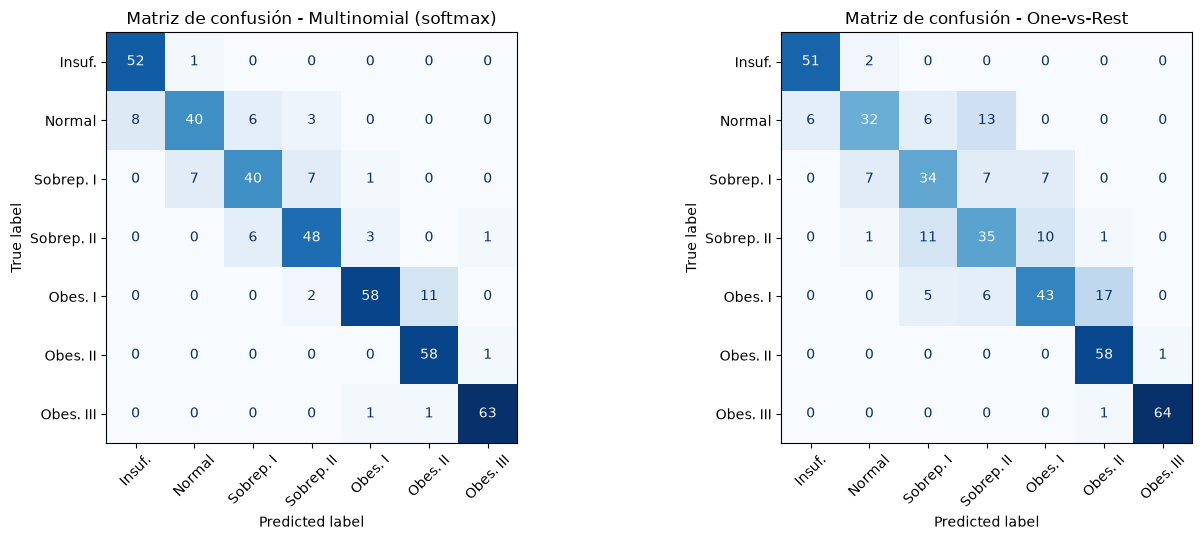

In [21]:
etiquetas_cortas = ["Insuf.", "Normal", "Sobrep. I", "Sobrep. II", "Obes. I", "Obes. II", "Obes. III"]

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
for eje, (nombre, modelo) in zip(ejes, estrategias.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_val, y_val,
        display_labels=etiquetas_cortas,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45,
        ax=eje
    )
    eje.set_title(f"Matriz de confusión - {nombre}")

plt.tight_layout()
plt.show()

**Observaciones (Punto 1.c)**

1. **La estrategia multinomial fue claramente superior** en el conjunto de validación: Accuracy de 0.859 frente a 0.758 y F1-score macro de 0.854 frente a 0.753 de One-vs-Rest. Los niveles de obesidad son clases **ordenadas y relacionadas entre sí**; al optimizar las 7 clases de forma conjunta, la softmax aprende fronteras que compiten entre clases vecinas, mientras que en OvR cada modelo binario resuelve un problema desbalanceado (1 clase contra 6) sin conocer a los demás.
2. **Calidad de las probabilidades:** la log-loss de la multinomial (0.47) es aproximadamente la mitad que la de OvR (0.84). Esto es coherente con la celda anterior: las 7 sigmoides de OvR sumaban valores como 1.46 o 0.41, y sklearn tuvo que normalizarlas artificialmente, mientras que la softmax entrega una distribución de probabilidad válida desde el propio modelo.
3. **Costo computacional:** ambas estrategias entrenan en fracciones de segundo en este dataset, pero OvR entrena 7 modelos en lugar de uno, por lo que su costo crece con el número de clases.
4. **Conclusión:** los resultados respaldan la decisión de sklearn de eliminar `multi_class` y usar siempre la formulación multinomial con 3 o más clases. One-vs-Rest sigue disponible mediante `OneVsRestClassifier` para los casos en que se necesite (por ejemplo, con solvers que solo resuelven problemas binarios).

### 4. Solver `'sag'` en la regresión logística (Punto 1.d)

El *solver* es el algoritmo de optimización que encuentra los pesos que minimizan la entropía cruzada. Como vimos en clase y en el punto 1.b, esta función de costo es **convexa**, por lo que el gradiente descendente puede encontrar el mínimo global. La diferencia entre solvers no está en *a dónde* llegan, sino en **cómo y qué tan rápido** recorren el camino hasta ese mínimo.

---

#### 4.1. Del gradiente descendente al SAG
Sea $f_i(\mathbf{w})$ la pérdida de la muestra $i$, de modo que $\mathcal{J}(\mathbf{w}) = \frac{1}{m}\sum_{i=1}^{m} f_i(\mathbf{w})$.

- **Gradiente descendente por lotes (*batch*)**, el implementado en el punto 1.b: en cada iteración usa las $m$ muestras,
$$\mathbf{w} \leftarrow \mathbf{w} - \alpha \, \frac{1}{m}\sum_{i=1}^{m} \nabla f_i(\mathbf{w})$$
Converge de forma estable, pero cada paso cuesta $O(m)$: con muchos datos se vuelve lento.

- **Gradiente descendente estocástico (SGD)**: usa una sola muestra aleatoria por paso,
$$\mathbf{w} \leftarrow \mathbf{w} - \alpha \, \nabla f_i(\mathbf{w})$$
Cada paso es muy barato, pero el gradiente es ruidoso y la convergencia cerca del óptimo es lenta.

- **SAG (*Stochastic Average Gradient*)**, propuesto por Schmidt, Le Roux y Bach (2013), combina lo mejor de ambos. Guarda en memoria el último gradiente calculado para **cada** muestra, $\mathbf{g}_i$, y su suma $\mathbf{d} = \sum_i \mathbf{g}_i$. En cada iteración:
  1. Selecciona aleatoriamente una muestra $i$.
  2. Recalcula **solo** el gradiente de esa muestra y actualiza la suma: $\;\mathbf{d} \leftarrow \mathbf{d} - \mathbf{g}_i + \nabla f_i(\mathbf{w})$, y luego $\mathbf{g}_i \leftarrow \nabla f_i(\mathbf{w})$.
  3. Da el paso con el **promedio** de todos los gradientes guardados:
$$\mathbf{w} \leftarrow \mathbf{w} - \frac{\alpha}{m}\,\mathbf{d}$$

Así, cada iteración cuesta lo mismo que un paso de SGD (un solo gradiente nuevo), pero la dirección del paso usa información de **todo** el conjunto de datos, como el gradiente por lotes. Para funciones suaves y fuertemente convexas, como la regresión logística con regularización L2, SAG alcanza **convergencia lineal**, mucho más rápida que la de SGD.

#### 4.2. Uso de `solver='sag'` en sklearn
```python
LogisticRegression(solver="sag", max_iter=..., tol=..., random_state=...)
```

| Aspecto | Comportamiento de `solver='sag'` |
|---|---|
| Penalización | Solo **L2** o sin regularización. Para L1 o Elastic-Net se usa `'saga'`, su versión mejorada (la que usamos en el punto 1.a). |
| Multiclase | Soporta la pérdida multinomial (softmax) del punto 1.c. |
| Escalado | La convergencia rápida **solo está garantizada si las variables tienen escalas similares**; por eso se combina con `StandardScaler` (nuestro `preprocesador`). |
| Tamaño de datos | Es más rápido que los demás solvers cuando el número de muestras y de variables es grande. En datasets pequeños, `lbfgs` suele ser suficiente. |
| `random_state` | Controla el orden aleatorio en que se recorren las muestras; solo tiene efecto en `sag`, `saga` y `liblinear`. |
| Tasa de aprendizaje | No hay que definirla: sklearn la calcula automáticamente a partir de la constante de Lipschitz de la pérdida. |
| `max_iter` | Cuenta **épocas** (pasadas completas sobre los datos), no muestras individuales. |
| Memoria | Guarda un gradiente por muestra, así que el consumo de memoria crece con $m$. |

In [22]:
import warnings
from sklearn.exceptions import ConvergenceWarning

def entrenar_con_solver(solver, escalar=True, max_iter=5000):
    # Entrena una regresión logística multinomial con regularización L2 (C=1, valor por defecto)
    # y registra el tiempo de entrenamiento y si el optimizador alcanzó la convergencia.
    pasos = [("preprocesamiento", clone(preprocesador))] if escalar else []
    pasos.append(("clasificador", LogisticRegression(
        solver=solver,
        max_iter=max_iter,
        random_state=SEMILLA
    )))
    modelo = Pipeline(pasos)

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        inicio = time.perf_counter()
        modelo.fit(X_train, y_train)
        tiempo = time.perf_counter() - inicio

    convergio = not any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos)
    return modelo, tiempo, convergio

#### 4.3. Comparación de `sag` con otros solvers
Se entrena el mismo modelo (multinomial, L2, C=1, datos escalados) con tres solvers. Como el problema es convexo, **todos deben llegar prácticamente a los mismos pesos**; lo que cambia es el número de iteraciones y el tiempo.

In [23]:
modelos_por_solver = {}
filas = []

for solver in ["lbfgs", "sag", "saga"]:
    modelo, tiempo, convergio = entrenar_con_solver(solver)
    modelos_por_solver[solver] = modelo
    filas.append({
        "Solver": solver,
        "Iteraciones": int(modelo.named_steps["clasificador"].n_iter_.max()),
        "¿Convergió?": "Sí" if convergio else "No",
        "Tiempo (s)": tiempo,
        "F1-score macro": f1_score(y_val, modelo.predict(X_val), average="macro")
    })

comparacion_solvers = pd.DataFrame(filas)

# Diferencia máxima entre los pesos de cada solver y los de lbfgs (referencia)
pesos_referencia = modelos_por_solver["lbfgs"].named_steps["clasificador"].coef_
comparacion_solvers["Máx. diferencia de pesos vs lbfgs"] = [
    np.abs(modelos_por_solver[s].named_steps["clasificador"].coef_ - pesos_referencia).max()
    for s in comparacion_solvers["Solver"]
]

comparacion_solvers

,Solver,Iteraciones,¿Convergió?,Tiempo (s),F1-score macro,Máx. diferencia de pesos vs lbfgs
0,lbfgs,77,Sí,0.056358,0.853944,0.000000
1,sag,91,Sí,0.092588,0.853944,0.048656
2,saga,160,Sí,0.199420,0.853944,0.056312


#### 4.4. Importancia del escalado para `sag`
Se entrena `sag` con y sin `StandardScaler`. Sin escalado, variables como `Weight` (decenas de kg) y `Height` (alrededor de 1.7 m) tienen magnitudes muy distintas, lo que obliga a usar una tasa de aprendizaje pequeña y vuelve lenta la convergencia.

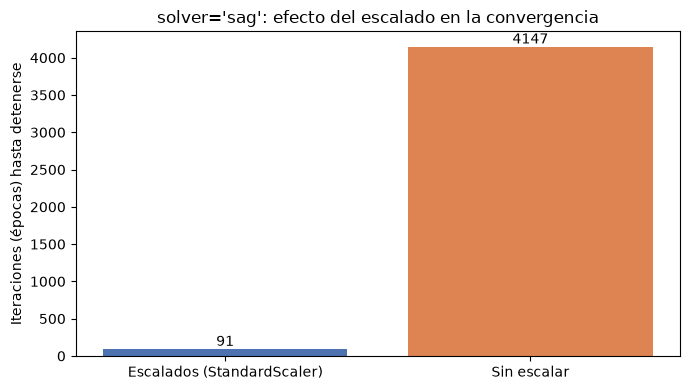

,Datos,Iteraciones,¿Convergió?,Tiempo (s),F1-score macro
0,Escalados (StandardScaler),91,Sí,0.092332,0.853944
1,Sin escalar,4147,Sí,3.395681,0.768597


In [24]:
filas_escalado = []

for escalar in [True, False]:
    modelo, tiempo, convergio = entrenar_con_solver("sag", escalar=escalar)
    filas_escalado.append({
        "Datos": "Escalados (StandardScaler)" if escalar else "Sin escalar",
        "Iteraciones": int(modelo.named_steps["clasificador"].n_iter_.max()),
        "¿Convergió?": "Sí" if convergio else "No (alcanzó max_iter)",
        "Tiempo (s)": tiempo,
        "F1-score macro": f1_score(y_val, modelo.predict(X_val), average="macro")
    })

efecto_escalado = pd.DataFrame(filas_escalado)

fig, eje = plt.subplots(figsize=(7, 4))
eje.bar(efecto_escalado["Datos"], efecto_escalado["Iteraciones"], color=["#4C72B0", "#DD8452"])
eje.set_ylabel("Iteraciones (épocas) hasta detenerse")
eje.set_title("solver='sag': efecto del escalado en la convergencia")
for posicion, valor in enumerate(efecto_escalado["Iteraciones"]):
    eje.text(posicion, valor, str(valor), ha="center", va="bottom")
plt.tight_layout()
plt.show()

efecto_escalado

**Observaciones (Punto 1.d)**

1. **Todos los solvers llegan al mismo óptimo.** `lbfgs`, `sag` y `saga` obtuvieron exactamente el mismo F1-score macro (0.854) y sus pesos difieren en menos de 0.06, diferencia que se explica por la tolerancia de parada (`tol`) de cada algoritmo. Esto confirma en la práctica la convexidad de la entropía cruzada: el solver cambia el camino, no el destino.
2. **En este dataset `sag` no es el más rápido.** Con aproximadamente 1.460 muestras de entrenamiento y 19 variables, `lbfgs` necesitó 77 iteraciones y `sag` 91 (los tiempos exactos varían según el equipo). Es el comportamiento esperado: la ventaja de `sag` aparece cuando el número de muestras y de variables es grande, porque cada iteración procesa un solo gradiente nuevo en lugar de todo el conjunto.
3. **El escalado es determinante para `sag`.** Sin `StandardScaler`, el solver necesitó 4.147 épocas frente a 91 con datos escalados (unas 45 veces más), y el tiempo de entrenamiento pasó de menos de 0.1 s a más de 3 s. Además, el F1-score macro bajó de 0.854 a 0.769: la penalización L2 depende de la escala de las variables, por lo que sin escalar el modelo regulariza de forma desigual y termina en una solución distinta y peor.
4. **Cuándo usar `solver='sag'`:** datasets grandes (muchas muestras y variables), con regularización L2 o sin regularización, y siempre con las variables escaladas. Si se necesita L1 o Elastic-Net, la alternativa es `saga`; para datasets pequeños como el nuestro, `lbfgs` es suficiente.

## 5. SGDClassifier de sklearn (Punto 1.e)

La clase `SGDClassifier` de scikit-learn implementa un **clasificador lineal entrenado con descenso de gradiente estocástico (SGD)**. Conviene tener claro que SGD es el *método de optimización* y no un modelo en sí: el modelo que se obtiene depende de la función de pérdida (`loss`). Con `loss='log_loss'` se entrena una regresión logística, con `loss='hinge'` (el valor por defecto) una máquina de vectores de soporte (SVM) lineal y con `loss='perceptron'` un perceptrón.

En todos los casos el modelo es lineal, $z = \mathbf{w}^T\mathbf{x} + b$, y minimiza una pérdida regularizada:
$$E(\mathbf{w}, b) = \frac{1}{n}\sum_{i=1}^{n} L\big(y_i,\; \mathbf{w}^T\mathbf{x}_i + b\big) + \alpha\, R(\mathbf{w})$$

donde $L$ es la pérdida, $R$ la penalización (L1, L2 o Elastic-Net, como en el punto 1.a) y $\alpha$ su intensidad. Con $R = \tfrac{1}{2}\lVert\mathbf{w}\rVert_2^2$, $\alpha$ se relaciona con el `C` de `LogisticRegression` mediante $\alpha = \frac{1}{C\,n}$, el mismo $\lambda$ del punto 1.a.

### 5.1. ¿Cómo funciona?

El algoritmo comienza inicializando los coeficientes del modelo. Posteriormente, realiza los siguientes pasos:

1. Selecciona una muestra del conjunto de entrenamiento (elegida al azar).

2. Calcula la predicción del modelo utilizando los coeficientes actuales.

3. Calcula el error mediante la función de pérdida.

4. Calcula el gradiente de la función de pérdida respecto a los parámetros, **usando solo esa muestra**.

5. Actualiza los coeficientes en dirección opuesta al gradiente.

6. Repite el procedimiento hasta alcanzar el número máximo de épocas (`max_iter`) o cumplir el criterio de convergencia (`tol`).

Una **época** es una pasada completa por todas las muestras; en cada época se recorren en orden aleatorio (`shuffle=True`). A diferencia del gradiente descendente por lotes del punto 1.b, que usa las $m$ muestras en cada paso, SGD da muchos pasos baratos pero ruidosos.

La actualización de los parámetros, incluyendo la regularización, se representa mediante la siguiente expresión:

$$\mathbf{w}_{t+1} = \mathbf{w}_t - \eta_t \Big[\nabla_{\mathbf{w}} L\big(y_i,\; \mathbf{w}_t^T\mathbf{x}_i + b_t\big) + \alpha\, \nabla R(\mathbf{w}_t)\Big]$$

Donde:

* $\mathbf{w}_t$: conjunto de coeficientes actuales del modelo.
* $\eta_t$: tasa de aprendizaje (*learning rate*), que puede cambiar en cada paso $t$ según la estrategia elegida (ver 5.2).
* $L$: pérdida de la muestra $i$ elegida en ese paso, y $\nabla R$ el gradiente de la penalización ($\mathbf{w}$ para L2, $\text{signo}(\mathbf{w})$ para L1).
* $\mathbf{w}_{t+1}$: nuevos coeficientes después de la actualización.

La tasa de aprendizaje determina el tamaño de los pasos que realiza el algoritmo durante la optimización. Si es demasiado grande, puede dificultar la convergencia; si es demasiado pequeña, el entrenamiento puede ser lento.

**Comparación con los métodos vistos en los puntos 1.b y 1.d:**

| Método | Gradiente usado en cada paso | Costo por paso | Ruido | Memoria |
|---|---|---|---|---|
| Gradiente descendente por lotes (1.b) | Promedio de las $m$ muestras | $O(m)$ | Ninguno | Baja |
| **SGD (`SGDClassifier`)** | De **una** muestra | $O(1)$ | Alto: la pérdida fluctúa entre pasos | Baja |
| SAG (`solver='sag'`, 1.d) | Promedio de los últimos gradientes guardados de cada muestra | $O(1)$ | Bajo | Alta (un gradiente por muestra) |

### 5.2. Parámetros principales

| Parámetro | Qué controla |
|---|---|
| `loss` | Función de pérdida y, con ella, el tipo de modelo (ver tabla siguiente) |
| `penalty`, `alpha`, `l1_ratio` | Tipo (`'l2'` por defecto, `'l1'`, `'elasticnet'`) e intensidad ($\alpha$, `0.0001` por defecto) de la regularización |
| `learning_rate`, `eta0`, `power_t` | Estrategia de la tasa de aprendizaje (ver más abajo) |
| `max_iter`, `tol` | Máximo de épocas y tolerancia de parada. Si `tol=None` se entrenan siempre las `max_iter` épocas |
| `shuffle`, `random_state` | Mezclar las muestras en cada época y fijar la semilla (el resultado cambia con ella porque el método es aleatorio) |
| `early_stopping`, `validation_fraction`, `n_iter_no_change` | Detener el entrenamiento cuando el puntaje en una porción de validación deja de mejorar |
| `average` | Si es `True`, usa el promedio de los pesos de todos los pasos (SGD promediado), lo que suaviza el ruido |
| `class_weight` | Pesos por clase para datos desbalanceados |
| `n_jobs`, `warm_start` | Paralelizar las clasificaciones One-vs-Rest y continuar un entrenamiento previo |

**Funciones de pérdida (`loss`) para clasificación**

| `loss` | Modelo que se entrena | ¿`predict_proba`? |
|---|---|---|
| `'hinge'` (por defecto) | SVM lineal | No |
| `'log_loss'` | Regresión logística | Sí |
| `'modified_huber'` | Variante suave de `hinge`, tolera mejor los valores atípicos | Sí |
| `'squared_hinge'` | Como `hinge`, pero penaliza el error al cuadrado | No |
| `'perceptron'` | Perceptrón | No |

`SGDClassifier` también acepta pérdidas pensadas para regresión (`'squared_error'`, `'huber'`, `'epsilon_insensitive'`), que no se usan aquí.

**Estrategias de la tasa de aprendizaje (`learning_rate`)**

| Valor | Tasa $\eta_t$ |
|---|---|
| `'optimal'` (por defecto) | $\eta_t = \dfrac{1}{\alpha\,(t_0 + t)}$: se calcula a partir de $\alpha$ y decrece con $t$; no requiere `eta0` |
| `'constant'` | $\eta_t = \eta_0$ |
| `'invscaling'` | $\eta_t = \dfrac{\eta_0}{t^{\,\text{power\_t}}}$ |
| `'adaptive'` | $\eta_t = \eta_0$ mientras la pérdida siga bajando; si deja de mejorar, se divide entre 5 |

**Métodos:** `fit`, `predict`, `decision_function` y, solo con algunas pérdidas, `predict_proba`. Además `partial_fit`, que actualiza el modelo con un lote de datos sin reentrenar desde cero, lo que permite el **aprendizaje en línea** y entrenar con datos que no caben en memoria.

### 5.3. Clasificación multiclase

`SGDClassifier` resuelve problemas con más de dos clases **solo con la estrategia One-vs-Rest** (punto 1.c): entrena una clasificación binaria por clase (en este dataset, 7), cada una con su vector de pesos. **No existe una versión multinomial (softmax)**, aunque se use `loss='log_loss'`. Esto condiciona los resultados, como se verá en el experimento.

### 5.4. Experimentos

Se usan los mismos datos, la misma partición y el mismo preprocesamiento (`StandardScaler`, necesario porque SGD es muy sensible a la escala de las variables) que en los puntos anteriores. Para que sea comparable con `LogisticRegression(C=1)`, se usa $\alpha = \frac{1}{C\,n} = \frac{1}{n}$.

#### 5.4.1. SGD frente a la regresión logística

In [31]:
from sklearn.linear_model import SGDClassifier

n_train = len(X_train)
alpha_equivalente = 1 / (1 * n_train)   # equivale a C = 1 en LogisticRegression: alpha = 1 / (C * n)

def entrenar_sgd(**parametros):
    # Entrena un SGDClassifier con el mismo preprocesamiento; devuelve el modelo y el tiempo
    config = dict(loss="log_loss", alpha=alpha_equivalente, max_iter=300, tol=None, random_state=SEMILLA)
    config.update(parametros)
    modelo = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", SGDClassifier(**config))
    ])
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    return modelo, time.perf_counter() - inicio

def resumen_validacion(nombre, modelo, tiempo):
    prediccion = modelo.predict(X_val)
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_val, prediccion),
        "F1-score macro": f1_score(y_val, prediccion, average="macro"),
        "Tiempo de entrenamiento (s)": tiempo
    }

sgd_log, tiempo_sgd = entrenar_sgd()

pd.DataFrame([
    resumen_validacion("LogisticRegression multinomial", modelo_multinomial, tiempos["Multinomial (softmax)"]),
    resumen_validacion("LogisticRegression One-vs-Rest", modelo_ovr, tiempos["One-vs-Rest"]),
    resumen_validacion("SGDClassifier (log_loss, 300 épocas)", sgd_log, tiempo_sgd),
])

,Modelo,Accuracy,F1-score macro,Tiempo de entrenamiento (s)
0,LogisticRegression multinomial,0.858852,0.853944,0.150994
1,LogisticRegression One-vs-Rest,0.758373,0.752661,0.290568
2,"SGDClassifier (log_loss, 300 épocas)",0.758373,0.752592,1.432315


In [32]:
clf_sgd = sgd_log.named_steps["clasificador"]
pesos_sgd = clf_sgd.coef_
pesos_ovr = np.vstack([estimador.coef_ for estimador in clf_ovr.estimators_])
pesos_multinomial = clf_multinomial.coef_

print("Forma de coef_ en SGDClassifier:", pesos_sgd.shape, "-> un vector de pesos por clase (One-vs-Rest)")
print(f"Correlación de los pesos de SGD con los de One-vs-Rest:  {np.corrcoef(pesos_sgd.ravel(), pesos_ovr.ravel())[0, 1]:.4f}")
print(f"Correlación de los pesos de SGD con los de multinomial: {np.corrcoef(pesos_sgd.ravel(), pesos_multinomial.ravel())[0, 1]:.4f}")

coincidencia = (sgd_log.predict(X_val) == modelo_ovr.predict(X_val)).mean()
print(f"Predicciones de SGD idénticas a las de One-vs-Rest en validación: {coincidencia:.2%}")
print("Suma de predict_proba de SGD (log_loss):", sgd_log.predict_proba(X_val.iloc[:3]).sum(axis=1).round(3))

Forma de coef_ en SGDClassifier: (7, 19) -> un vector de pesos por clase (One-vs-Rest)
Correlación de los pesos de SGD con los de One-vs-Rest:  0.9984
Correlación de los pesos de SGD con los de multinomial: 0.8521
Predicciones de SGD idénticas a las de One-vs-Rest en validación: 99.28%
Suma de predict_proba de SGD (log_loss): [1. 1. 1.]


#### 5.4.2. Efecto de la función de pérdida

In [33]:
filas = []
for perdida in ["hinge", "log_loss", "modified_huber", "perceptron", "squared_hinge"]:
    modelo, tiempo = entrenar_sgd(loss=perdida)
    fila = resumen_validacion(perdida, modelo, tiempo)
    fila["¿predict_proba?"] = "Sí" if hasattr(modelo, "predict_proba") else "No"
    filas.append(fila)

pd.DataFrame(filas).rename(columns={"Modelo": "loss"})

,loss,Accuracy,F1-score macro,Tiempo de entrenamiento (s),¿predict_proba?
0,hinge,0.696172,0.683156,0.841563,No
1,log_loss,0.758373,0.752592,0.919334,Sí
2,modified_huber,0.755981,0.757888,0.453146,Sí
3,perceptron,0.636364,0.637315,0.425275,No
4,squared_hinge,0.665072,0.674163,0.417319,No


#### 5.4.3. Efecto de la tasa de aprendizaje

In [34]:
estrategias_lr = {
    "optimal (por defecto)": {},
    "constant (eta0 = 0.01)": dict(learning_rate="constant", eta0=0.01),
    "invscaling (eta0 = 0.1)": dict(learning_rate="invscaling", eta0=0.1),
    "adaptive (eta0 = 0.01)": dict(learning_rate="adaptive", eta0=0.01),
}

filas = []
for nombre, parametros in estrategias_lr.items():
    modelo, tiempo = entrenar_sgd(**parametros)
    filas.append(resumen_validacion(nombre, modelo, tiempo))

pd.DataFrame(filas).rename(columns={"Modelo": "learning_rate"})

,learning_rate,Accuracy,F1-score macro,Tiempo de entrenamiento (s)
0,optimal (por defecto),0.758373,0.752592,0.742213
1,constant (eta0 = 0.01),0.751196,0.743076,0.751867
2,invscaling (eta0 = 0.1),0.677033,0.665450,0.873274
3,adaptive (eta0 = 0.01),0.751196,0.743076,0.763712


#### 5.4.4. Efecto de `alpha` y de la penalización
Se evalúa con validación cruzada de 5 particiones (la misma del punto 1.a) y F1 macro, de forma análoga a lo hecho con `C` en la regresión logística.

,l2,l1,elasticnet
alpha,,,
0.000001,0.6408,0.6391,0.6006
0.000010,0.6743,0.6522,0.6707
0.000100,0.7035,0.7188,0.7009
0.001000,0.7333,0.7635,0.7309
0.010000,0.6725,0.6947,0.6725
0.100000,0.5258,0.2839,0.5048


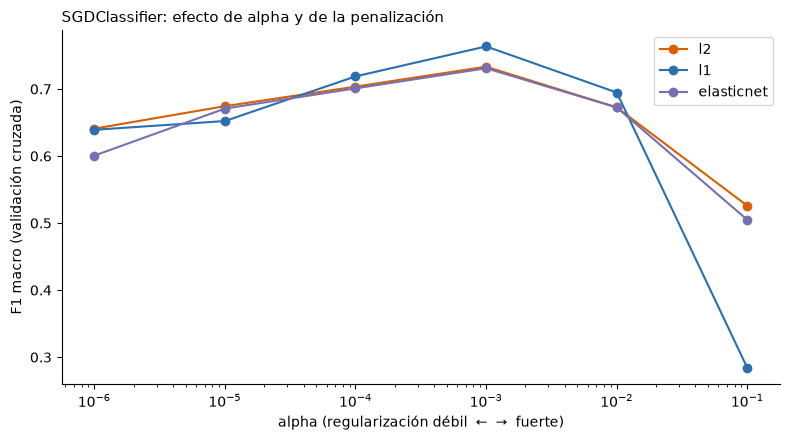

In [35]:
from joblib import Parallel, delayed

alphas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
penalizaciones = ["l2", "l1", "elasticnet"]

def f1_cv_sgd(penalizacion, alpha):
    modelo = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", SGDClassifier(loss="log_loss", penalty=penalizacion, alpha=alpha,
                                       max_iter=1000, tol=1e-4, random_state=SEMILLA))
    ])
    return cross_val_score(modelo, X_train, y_train, cv=cv, scoring="f1_macro").mean()

combinaciones = [(pen, a) for pen in penalizaciones for a in alphas]
valores = Parallel(n_jobs=-1)(delayed(f1_cv_sgd)(pen, a) for pen, a in combinaciones)
tabla_alpha = pd.Series(valores, index=pd.MultiIndex.from_tuples(combinaciones)).unstack(0)[penalizaciones]
tabla_alpha.index.name = "alpha"
display(tabla_alpha.round(4))

fig, eje = plt.subplots(figsize=(8, 4.5))
for pen, color in zip(penalizaciones, ["#d95f02", "#2a6fb0", "#7570b3"]):
    eje.plot(alphas, tabla_alpha[pen], marker="o", color=color, label=pen)
eje.set_xscale("log")
eje.set_xlabel("alpha (regularización débil  ←  →  fuerte)")
eje.set_ylabel("F1 macro (validación cruzada)")
eje.set_title("SGDClassifier: efecto de alpha y de la penalización", loc="left", fontsize=11)
eje.legend()
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

#### 5.4.5. Aprendizaje en línea con `partial_fit`
Se entrena el modelo por lotes pequeños (unas 97 muestras cada uno) sin ver nunca el conjunto completo de una vez, y se mide el F1 macro en validación después de cada época.

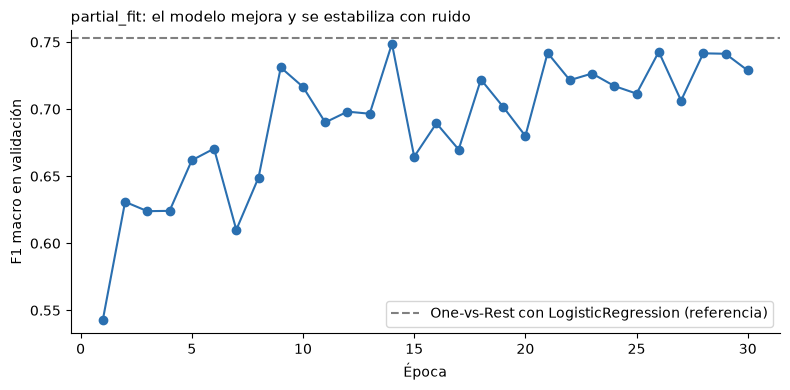

F1 macro en la época 1: 0.543 | época 30: 0.729 | mín.-máx. entre las épocas 20 y 30: 0.680 - 0.743


In [36]:
preprocesador_pf = clone(preprocesador).fit(X_train)
X_train_pf = preprocesador_pf.transform(X_train)
X_val_pf = preprocesador_pf.transform(X_val)

modelo_pf = SGDClassifier(loss="log_loss", alpha=alpha_equivalente, random_state=SEMILLA)
rng = np.random.default_rng(SEMILLA)
f1_por_epoca = []

for epoca in range(30):
    for lote in np.array_split(rng.permutation(len(y_train)), 15):      # 15 lotes por época
        modelo_pf.partial_fit(X_train_pf[lote], y_train.values[lote], classes=np.arange(7))
    f1_por_epoca.append(f1_score(y_val, modelo_pf.predict(X_val_pf), average="macro"))

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(range(1, 31), f1_por_epoca, marker="o", color="#2a6fb0")
eje.axhline(f1_score(y_val, modelo_ovr.predict(X_val), average="macro"), color="gray", ls="--",
            label="One-vs-Rest con LogisticRegression (referencia)")
eje.set_xlabel("Época")
eje.set_ylabel("F1 macro en validación")
eje.set_title("partial_fit: el modelo mejora y se estabiliza con ruido", loc="left", fontsize=11)
eje.legend()
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

print(f"F1 macro en la época 1: {f1_por_epoca[0]:.3f} | época 30: {f1_por_epoca[-1]:.3f} | "
      f"mín.-máx. entre las épocas 20 y 30: {min(f1_por_epoca[19:]):.3f} - {max(f1_por_epoca[19:]):.3f}")

**Observaciones (Punto 1.e)**

1. **SGD llega a la solución de One-vs-Rest, no a la de la regresión logística multinomial.** Con `loss='log_loss'` y 300 épocas, `SGDClassifier` obtiene un F1 macro de 0,7526, prácticamente igual al de One-vs-Rest con `LogisticRegression` (0,7527) y muy por debajo del multinomial (0,8539). Sus pesos están casi perfectamente correlacionados con los de One-vs-Rest (0,998) y mucho menos con los del multinomial (0,852), y sus predicciones coinciden con las de One-vs-Rest en el 99,28 % de la validación. La diferencia con el multinomial no es falta de entrenamiento: `SGDClassifier` no tiene formulación multinomial (ver 5.3 y las observaciones del punto 1.c).
2. **Para este dataset SGD no es la mejor herramienta.** Es más lento que `lbfgs` (0,77 s frente a 0,08 s en esta ejecución) y menos preciso. Su ventaja aparece con muchísimas muestras (cada paso cuesta lo mismo sin importar el tamaño del conjunto), con datos que llegan por lotes o que no caben en memoria (`partial_fit`); con 1.460 muestras de entrenamiento no se aprovecha.
3. **La función de pérdida define el modelo.** En validación, `modified_huber` (F1 macro 0,758) y `log_loss` (0,753) rindieron mejor que `hinge` (0,683), `squared_hinge` (0,674) y `perceptron` (0,637). Además son las únicas que permiten `predict_proba`. La diferencia entre `modified_huber` y `log_loss` (0,005) es demasiado pequeña para concluir algo, porque se midió con una sola partición y una sola semilla.
4. **La tasa de aprendizaje importa.** `optimal` (la de por defecto) fue la mejor (0,7526); `constant` y `adaptive` con `eta0` = 0,01 dieron 0,7431 (resultados idénticos, probablemente porque la tasa adaptativa nunca llegó a reducirse) e `invscaling` con `eta0` = 0,1 fue la peor (0,6655). Con `constant`, `invscaling` y `adaptive` hay que ajustar `eta0`, mientras que `optimal` no lo necesita.
5. **`alpha` y penalización.** Con validación cruzada, las tres penalizaciones alcanzan su mejor F1 con `alpha` = 0,001 (L1: 0,7635; L2: 0,7333; Elastic-Net: 0,7309), cerca del $\alpha = 1/(C\,n) \approx 0{,}0007$ que equivale a `C` = 1. Tanto muy poca regularización (`alpha` = $10^{-6}$) como demasiada (`alpha` = 0,1) empeoran el resultado; con `alpha` = 0,1, L1 colapsa (0,2839) porque anula casi todos los pesos, igual que `C` muy pequeño en el punto 1.a. El máximo (≈ 0,76) queda lejos del ≈ 0,95 que alcanzó la regresión logística multinomial en el punto 1.a.
6. **`partial_fit`.** Entrenando por lotes pequeños, el F1 macro sube de 0,543 en la época 1 a 0,729 en la época 30 y oscila entre 0,680 y 0,743 entre las épocas 20 y 30, el ruido típico de SGD. Termina cerca de la referencia One-vs-Rest (0,753) sin haber usado nunca todo el conjunto de una vez, lo que muestra que el modelo se puede actualizar de forma incremental.
7. **Conclusión.** `SGDClassifier` es la opción adecuada para conjuntos muy grandes o con datos en flujo, siempre con variables escaladas y ajustando `alpha` y la tasa de aprendizaje. Para un dataset pequeño como este, `LogisticRegression` (multinomial) es más rápida y más precisa.

## 6. Codificación de variables categóricas (Punto 1.f)

Los algoritmos de aprendizaje automático operan con números, por lo que las variables categóricas (texto) deben transformarse en valores numéricos. La técnica elegida importa, porque determina qué relaciones entre categorías puede "ver" el modelo (orden, distancia). Se explican tres formas, ilustradas con variables reales de este dataset:

| Técnica | Tipo de variable adecuada | Ejemplo en el dataset | Herramienta en sklearn |
|---|---|---|---|
| Binaria (mapeo 0/1) | Dos categorías | `Gender`, `FAVC`, `SMOKE` | `OneHotEncoder(drop='if_binary')` u `OrdinalEncoder` |
| Ordinal | Categorías con un orden natural | `CAEC`, `CALC` | `OrdinalEncoder(categories=[...])` |
| One-Hot | Categorías sin orden (nominales) | `MTRANS` | `OneHotEncoder` |

### 6.1. Codificación binaria (mapeo 0/1)

Esta técnica consiste en reemplazar las categorías de una variable que tiene únicamente dos valores posibles por números binarios, generalmente 0 y 1


Por ejemplo, en nuestro conjunto de datos, la variable `Gender` contiene dos categorías: `Female` y `Male`. Podemos transformarlas de la siguiente manera:

| Categoría original | Valor codificado |
| --- | --- |
| `Female` | 0 |
| `Male` | 1 |

**Ventajas:**

- Es sencilla de implementar y comprender.

- No aumenta la cantidad de columnas del conjunto de datos.

- Reduce el consumo de memoria.

- Es adecuada para variables que tienen únicamente dos categorías.

**Desventajas:**

- No es apropiada para variables con múltiples categorías nominales.

- Los valores numéricos pueden generar una interpretación de orden o distancia que no necesariamente existe.

> **Aclaración de nombres.** Aquí "binaria" significa mapear dos categorías a 0 y 1. No debe confundirse con el *Binary Encoding* de la librería `category_encoders`, que es otra técnica: convierte el índice entero de cada categoría a su representación en bits y la reparte en varias columnas.

### 6.2. Codificación Ordinal

La codificación ordinal consiste en asignar un valor numérico a cada categoría siguiendo un orden determinado.

Se utiliza cuando las categorías representan niveles o frecuencias que tienen una relación jerárquica.

En nuestro dataset encontramos la variable CAEC, que representa la frecuencia con la que una persona consume alimentos entre comidas.

Su transformación se realizó de la siguiente manera:

| Categoría original | Valor codificado |
| --- | --- |
| No | 0 |
| Sometimes | 1 |
| Frequently | 2 |
| Always | 3 |

En sklearn se define el orden de forma explícita para que no sea alfabético: `OrdinalEncoder(categories=[["no", "Sometimes", "Frequently", "Always"]])`. Si no se indica, el orden se asigna alfabéticamente, lo que carece de sentido para variables como esta.

**Ventajas:**

- Conserva el orden natural de las categorías.

- No aumenta la cantidad de columnas.

- Es útil cuando las categorías representan niveles, frecuencias o escalas.

**Desventajas:**

- Puede introducir una relación de distancia numérica que no necesariamente existe entre las categorías.

- La asignación de valores depende de conocer correctamente el orden de las categorías.

- Si se utiliza en variables nominales, puede introducir relaciones artificiales que afecten el aprendizaje del modelo.

### 6.3. Codificación One-Hot Encoding

One-Hot Encoding es una técnica que transforma una variable categórica en múltiples columnas binarias, creando una columna independiente para cada categoría.

Cada columna representa la presencia o ausencia de una categoría mediante los valores 1 y 0, respectivamente.
En nuestro conjunto de datos se aplicó esta técnica sobre la variable `MTRANS` , que representa el medio de transporte utilizado por las personas.

De esta manera, una variable categórica se transforma en varias columnas binarias (conocido comúnmente como *One-Hot Encoding*).

Por ejemplo, si las categorías fueran `Automobile`, `Public_Transportation` y `Two_Wheels`, la transformación sería:

| Automobile | Public_Transportation | Two_Wheels |
| --- | --- | --- |
| 1 | 0 | 0 |
| 0 | 1 | 0 |
| 0 | 0 | 1 |

Cada fila tiene un valor de 1 en la columna correspondiente a su categoría y 0 en las demás.

En sklearn se usa `OneHotEncoder`. Para modelos lineales con intercepto se puede agregar `drop='first'` (elimina una categoría de cada variable), con lo que se evita la multicolinealidad perfecta (la "trampa de la variable ficticia"), porque la última columna se puede deducir de las demás. Con `handle_unknown='ignore'` el modelo tolera categorías que no vio en el entrenamiento.

**Ventajas**

- No establece relaciones de orden artificial entre categorías nominales.

- Permite representar variables con múltiples categorías.

- Es compatible con diferentes algoritmos de aprendizaje automático.

- Facilita la interpretación de la influencia de cada categoría en el modelo.

**Desventajas:**

- Aumenta la cantidad de columnas del conjunto de datos.

- Puede incrementar el consumo de memoria cuando existen muchas categorías.

- Puede generar problemas de multicolinealidad en determinados modelos si se conservan todas las categorías.

- Puede producir matrices con muchos valores en cero cuando existen numerosas categorías.

### 6.4. Las tres técnicas aplicadas a datos reales

In [37]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

muestra = dataset[["Gender", "CAEC", "MTRANS"]].head(6).reset_index(drop=True)

# 1) Binaria: Gender -> una columna 0/1
binaria = pd.DataFrame(
    OneHotEncoder(drop="if_binary").fit_transform(muestra[["Gender"]]).toarray(),
    columns=["Gender_Male"]
)

# 2) Ordinal: CAEC -> un entero respetando el orden natural
ordinal = pd.DataFrame(
    OrdinalEncoder(categories=[["no", "Sometimes", "Frequently", "Always"]]).fit_transform(muestra[["CAEC"]]),
    columns=["CAEC (ordinal)"]
)

# 3) One-Hot: MTRANS -> una columna por categoría
codificador_oh = OneHotEncoder(dtype=int).fit(dataset[["MTRANS"]])
one_hot = pd.DataFrame(
    codificador_oh.transform(muestra[["MTRANS"]]).toarray(),
    columns=[c.replace("MTRANS_", "MTRANS=") for c in codificador_oh.get_feature_names_out()]
)

pd.concat([muestra, binaria, ordinal, one_hot], axis=1)

,Gender,CAEC,MTRANS,Gender_Male,CAEC (ordinal),MTRANS=Automobile,MTRANS=Bike,MTRANS=Motorbike,MTRANS=Public_Transportation,MTRANS=Walking
0,Female,Sometimes,Public_Transportation,0.0,1.0,0,0,0,1,0
1,Female,Sometimes,Public_Transportation,0.0,1.0,0,0,0,1,0
2,Male,Sometimes,Public_Transportation,1.0,1.0,0,0,0,1,0
3,Male,Sometimes,Walking,1.0,1.0,0,0,0,0,1
4,Male,Sometimes,Public_Transportation,1.0,1.0,0,0,0,1,0
5,Male,Sometimes,Automobile,1.0,1.0,1,0,0,0,0


### 6.5. ¿Importa la codificación? Comparación en el dataset

Para comparar las técnicas se codifican todas las variables categóricas de tres formas y se entrena el mismo modelo con cada una:

- **Ordinal para todo:** cada categoría se reemplaza por un entero, también en las variables nominales (como `MTRANS`), donde el orden es alfabético y por tanto arbitrario.
- **One-Hot para todo:** una columna por categoría, también en `CAEC` y `CALC`, que sí tienen orden (se pierde esa información).
- **Mixta (la que se usa en este notebook):** binaria para las variables de dos categorías, ordinal con orden explícito para `CAEC` y `CALC`, y One-Hot para `MTRANS`.

Se usan dos modelos, uno lineal (regresión logística), que interpreta los números como magnitudes, y uno basado en árboles (Random Forest), que solo compara umbrales. Cada uno se evalúa **con y sin `Weight` y `Height`**: con ellas el modelo acierta sobre todo gracias al IMC y la codificación casi no se nota (ver nota del punto 1.a); sin ellas, las variables categóricas pesan más.

In [38]:
from sklearn.ensemble import RandomForestClassifier

# CALC = "Always" tiene un solo registro: en algunos pliegues solo cae en la parte de prueba y One-Hot lo
# codifica como ceros (handle_unknown="ignore"). Es el comportamiento esperado, así que se silencia el aviso.
warnings.filterwarnings("ignore", message="Found unknown categories", category=UserWarning)

columnas_num = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
columnas_bin = ["Gender", "family_history_with_overweight", "FAVC", "SMOKE", "SCC"]
columnas_ord = ["CAEC", "CALC"]
columnas_nom = ["MTRANS"]
orden_frecuencia_texto = ["no", "Sometimes", "Frequently", "Always"]

def con_categorias_originales(indices):
    # Variables numéricas ya codificadas + variables categóricas con su texto original
    tabla = data.loc[indices, columnas_num].copy()
    for columna in columnas_bin + columnas_ord + columnas_nom:
        tabla[columna] = dataset.loc[indices, columna].values
    return tabla

A_train = con_categorias_originales(X_train.index)
A_val = con_categorias_originales(X_val.index)

def ordinal_escalado(**parametros):
    return Pipeline([("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, **parametros)),
                     ("escalado", StandardScaler())])

def construir_transformador(estrategia, numericas):
    if estrategia == "Ordinal para todo":
        categoricas = ("categoricas", ordinal_escalado(), columnas_bin + columnas_ord + columnas_nom)
        return ColumnTransformer([("numericas", StandardScaler(), numericas), categoricas])
    if estrategia == "One-Hot para todo":
        categoricas = ("categoricas", OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
                       columnas_bin + columnas_ord + columnas_nom)
        return ColumnTransformer([("numericas", StandardScaler(), numericas), categoricas])
    return ColumnTransformer([                                    # Mixta
        ("numericas", StandardScaler(), numericas),
        ("binarias", ordinal_escalado(), columnas_bin),
        ("ordinales", ordinal_escalado(categories=[orden_frecuencia_texto] * 2), columnas_ord),
        ("nominales", OneHotEncoder(handle_unknown="ignore"), columnas_nom),
    ])

modelos = {
    "Regresión logística": lambda: LogisticRegression(max_iter=5000, random_state=SEMILLA),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=200, random_state=SEMILLA, n_jobs=-1),
}

filas = []
for sin_peso_altura_flag in [False, True]:
    numericas = [c for c in columnas_num if not (sin_peso_altura_flag and c in ("Weight", "Height"))]
    for nombre_modelo, crear_modelo in modelos.items():
        for estrategia in ["Ordinal para todo", "One-Hot para todo", "Mixta"]:
            pipeline = Pipeline([("transformador", construir_transformador(estrategia, numericas)),
                                 ("modelo", crear_modelo())])
            puntajes = cross_val_score(pipeline, A_train, y_train, cv=cv, scoring="f1_macro")
            pipeline.fit(A_train, y_train)
            columnas_resultantes = pipeline.named_steps["transformador"].transform(A_train.iloc[:2]).shape[1]
            filas.append({
                "Weight y Height": "Sin ellas" if sin_peso_altura_flag else "Con ellas",
                "Modelo": nombre_modelo,
                "Codificación": estrategia,
                "Columnas": columnas_resultantes,
                "F1 macro CV": f"{puntajes.mean():.4f} ± {puntajes.std():.4f}",
                "F1 macro validación": round(f1_score(y_val, pipeline.predict(A_val), average="macro"), 4),
            })

pd.DataFrame(filas)

,Weight y Height,Modelo,Codificación,Columnas,F1 macro CV,F1 macro validación
0,Con ellas,Regresión logística,Ordinal para todo,16,0.8539 ± 0.0188,0.8533
1,Con ellas,Regresión logística,One-Hot para todo,26,0.8579 ± 0.0116,0.8704
2,Con ellas,Regresión logística,Mixta,20,0.8537 ± 0.0181,0.8535
3,Con ellas,Random Forest,Ordinal para todo,16,0.9408 ± 0.0103,0.9184
4,Con ellas,Random Forest,One-Hot para todo,26,0.9317 ± 0.0137,0.9254
5,Con ellas,Random Forest,Mixta,20,0.9303 ± 0.0167,0.9232
6,Sin ellas,Regresión logística,Ordinal para todo,14,0.5350 ± 0.0271,0.5492
7,Sin ellas,Regresión logística,One-Hot para todo,24,0.5591 ± 0.0203,0.6098
8,Sin ellas,Regresión logística,Mixta,18,0.5400 ± 0.0237,0.5750
9,Sin ellas,Random Forest,Ordinal para todo,14,0.7759 ± 0.0273,0.7684


**Observaciones (Punto 1.f)**

1. **En este dataset la codificación cambió poco el resultado.** Con `Weight` y `Height`, la regresión logística obtiene 0,854 (ordinal), 0,858 (One-Hot) y 0,854 (mixta) de F1 macro en validación cruzada, y Random Forest 0,941, 0,932 y 0,930. En todos los casos las diferencias son del orden de la desviación estándar entre particiones (0,01 a 0,02), por lo que no son concluyentes.
2. **Sin `Weight` ni `Height`, One-Hot es ligeramente mejor en el modelo lineal.** Obtiene 0,559 en validación cruzada frente a 0,535 (ordinal) y 0,540 (mixta), y 0,610 en validación frente a 0,549 y 0,575. La diferencia es de alrededor de una desviación estándar (0,02 a 0,03), así que es una tendencia y no una prueba. En Random Forest las tres codificaciones dan prácticamente lo mismo (0,776 a 0,784), como es de esperar, porque un árbol solo compara umbrales y no interpreta la magnitud de los números.
3. **Por qué podría favorecer al modelo lineal.** La codificación ordinal obliga a que toda la variable tenga un único peso y una distancia fija entre categorías. En `MTRANS`, donde el orden alfabético (Automobile < Bike < Motorbike < Public_Transportation < Walking) es arbitrario, esa distancia no tiene sentido; One-Hot da un peso propio a cada categoría. En `CAEC` y `CALC` ocurre lo contrario: el orden sí es real, y la codificación ordinal lo conserva con menos columnas.
4. **Costo de One-Hot.** Agrega columnas: 24 o 26 frente a 14 o 16 de la ordinal (y 18 o 20 de la mixta). Aquí no importa, pero crece con la cantidad de categorías.
5. **Decisión del notebook.** Se usa la codificación **mixta**, que respeta la naturaleza de cada variable: binaria para las variables de dos categorías, ordinal con orden explícito para `CAEC` y `CALC`, y One-Hot para `MTRANS`. Es la más fácil de justificar, aunque en este dataset no sea la que más rinde.

**Resumen de las tres técnicas**

| Técnica | Úsala cuando | Evítala cuando |
|---|---|---|
| **Binaria (0/1)** | La variable tiene dos categorías | Hay más de dos categorías sin orden |
| **Ordinal** | Hay un orden natural (por ejemplo `CAEC`, `CALC`) | Las categorías son nominales y el modelo es lineal o basado en distancias |
| **One-Hot** | Las categorías son nominales y de baja cardinalidad (por ejemplo `MTRANS`) | La cardinalidad es muy alta (cientos de categorías): el número de columnas se dispara y conviene otra técnica (agrupar categorías raras, *target encoding*, *hashing*) |